**<h1><center>Week 3 — Classes, Clusters & Hidden Structure</center></h1>**
<center>Course: Machine Learning For Signal Processing</center>
<center>Amirkabir University of Technology (Tehran Polytechnic) - Department of Electrical Engineering
</center>

---
Complementary notebook for module 1, week 3.  
Presented by: **Amirsadra Khodadadi**  

*If you have any questions, please contact the TAs.* 
___

# Instructions

### Requirements

This notebook uses Python and the following libraries:

- **NumPy** — Numerical computations, array operations, and simulations.
- **Matplotlib** — Data visualization.
- **SciPy** — Probability distributions, statistical calculations, and signal processing.
- **scikit-learn** — Gaussian classification, mixture models, and evaluation metrics.

You can install the required libraries using:

```bash
python -m pip install numpy matplotlib scipy scikit-learn


### Plotting Style

The notebook uses a custom color palette and an optional hand-drawn plotting style. The hand-drawn appearance is enabled using:

```python
plt.xkcd()
```
If you prefer standard Matplotlib plots, you can **comment out** the following lines in the initial setup cells:
```python
import logging
```
and:
```python
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.xkcd()
```

**Note:** The logging configuration suppresses warnings about missing XKCD fonts. It does not affect the numerical calculations.  
After changing the plotting style, restart the kernel and rerun the notebook to ensure that the new settings are applied.


### Reproducibility

The synthetic experiments use fixed random seeds to make the numerical results reproducible.  
Each experiment creates its own NumPy random-number generator using:
```python
rng = np.random.default_rng(seed)
```
This allows experiments to be rerun independently without unintentionally changing the random samples used in other sections.  
You are encouraged to modify the random seeds, noise levels, model parameters, and other experimental settings to investigate how the results change.  

**Important:** Numerical results may vary across random realizations, but the theoretical relationships should remain consistent under the stated assumptions.  
For the experiments involving real ECG data, the dataset selection and data-splitting procedures will also be specified explicitly to support reproducibility.


### Optional Investigations

Some experiments include sections labeled **Optional**.

These sections provide additional explanations, simulations, and opportunities for independent exploration.
They are not required for following the main TA session, although you are encouraged to modify simulation parameters, rerun the experiments, and compare their observations with the theoretical predictions.


## Imports and Modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy
import sklearn

from pathlib import Path

import logging     # simply for xkcd plots, can be commented out.

## Plot Settings

In [2]:
# Color palette
TEAL = "#0B5963"
RED = "#F08080"
GRAY = "#8D969C"
LIGHT_GRAY = "#D9DFE2"
YELLOW = "#E9BD42"
DARK = "#263238"

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": DARK,
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "text.color": DARK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

# simply for xkcd plots, can be commented out.
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR) 
plt.xkcd()  


## Global Configuration

In [3]:
BASE_SEED = 42

CLASS_NAMES = ("Normal", "High Load", "Abnormal")
CLASS_COLORS = (TEAL, RED, YELLOW)

print("Week 3 notebook setup completed.")
print(f"Base random seed: {BASE_SEED}")

Week 3 notebook setup completed.
Base random seed: 42


# Part I: Gaussian Recognition

## Experiment 1: Recognizing Operating Conditions from Noisy Signals

In this experiment, we investigate how the statistical assumptions of a classifier influence its learned decision rule.

We will:

1. Generate signals corresponding to three operating conditions.
2. Extract informative features from the observed waveforms.
3. Study the statistical distributions of those features.
4. Fit Gaussian classifiers using different covariance assumptions.
5. Compare their decision boundaries and classification performance.

The main methods will be:

- **Linear Discriminant Analysis (LDA):** A Gaussian classifier with a shared covariance matrix.
- **Quadratic Discriminant Analysis (QDA):** A Gaussian classifier with class-specific covariance matrices.

### 1.1 Problem Formulation

Consider a machine monitored using a vibration sensor.
Suppose the machine can operate under three conditions:
- **Normal operation**
- **High-load operation**
- **Abnormal operation**

We assume that the measured signal contains two harmonic components corrupted by additive noise.
For observation $i$:
$$
\boxed{
y_i[n]=
a_i\cos\left(2\pi f_0\frac{n}{f_s}\right)+
b_i\cos\left(4\pi f_0\frac{n}{f_s}\right)+
\epsilon_i[n]
}
$$
where:
- $f_s$ is the sampling frequency.
- $f_0$ is the fundamental frequency.
- $a_i$ is the coefficient of the fundamental harmonic.
- $b_i$ is the coefficient of the second harmonic.
- $\epsilon_i[n]$ is additive measurement noise.

We assume independent Gaussian noise:
$$
\epsilon_i[n]\sim\mathcal N(0,\sigma_\epsilon^2).
$$
The harmonic coefficients depend on the machine's operating condition.
Define the coefficient vector:
$$
\boldsymbol\beta_i=
\begin{bmatrix}
a_i\\
b_i
\end{bmatrix}.
$$
For each operating condition $C_i=k$, we assume:
$$
\boxed{
\boldsymbol\beta_i\mid C_i=k
\sim
\mathcal N(
\boldsymbol\mu_k,
\boldsymbol\Sigma_k
)
}
$$
Different operating conditions can therefore have different mean harmonic coefficients, covariance matrices, or both.


***Why This Model?***

The coefficients of harmonic components are a simple example of signal features that can carry information about an operating condition.
We intentionally use an idealized signal model rather than attempting to simulate the detailed physics of real bearing faults.
This provides a mathematically controlled setting in which:
- Class-conditional feature distributions can be characterized.
- Covariance assumptions can be examined explicitly.
- The behavior of LDA and QDA can be compared with known statistical assumptions.

The coefficients are initially unobserved. We will estimate them from the noisy waveforms using least squares.

**Goal:** Given a new noisy waveform, extract its harmonic coefficients and predict the operating condition.

### 1.2 Feature Extraction Using Least Squares


The observed signal can be written in matrix form:
$$
\mathbf y_i=
\boldsymbol\Phi\boldsymbol\beta_i+
\boldsymbol\epsilon_i,
$$
where the columns of $\boldsymbol\Phi$ contain the known harmonic basis functions:
$$
\boldsymbol\Phi=
\begin{bmatrix}
\cos(2\pi f_0t_0) & \cos(4\pi f_0t_0)\\
\cos(2\pi f_0t_1) & \cos(4\pi f_0t_1)\\
\vdots & \vdots\\
\cos(2\pi f_0t_{T-1}) & \cos(4\pi f_0t_{T-1})
\end{bmatrix},
$$
with $t_n=n/f_s$.
The least-squares estimate of the harmonic coefficients is
$$
\boxed{
\hat{\boldsymbol\beta}_i=
(\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}
\boldsymbol\Phi^T\mathbf y_i
}
$$
provided that $\boldsymbol\Phi$ has full column rank.
Our feature vector is therefore
$$
\boxed{
\mathbf x_i=
\hat{\boldsymbol\beta}_i=
\begin{bmatrix}
\hat a_i\\
\hat b_i
\end{bmatrix}.
}
$$

**Connection to Gaussian Classification**

Substituting the observation model into the least-squares estimator gives
$$
\hat{\boldsymbol\beta}_i=
\boldsymbol\beta_i+
(\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}
\boldsymbol\Phi^T\boldsymbol\epsilon_i.
$$
Because the underlying coefficients and measurement noise are Gaussian and independent, their sum is also Gaussian.
Consequently,
$$
\boxed{
\mathbf x_i\mid C_i=k
\sim
\mathcal N(
\boldsymbol\mu_k,
\boldsymbol\Sigma_k^{(x)}
)
}
$$
where
$$
\boldsymbol\Sigma_k^{(x)}=
\boldsymbol\Sigma_k+
\sigma_\epsilon^2
(\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}.
$$

In [ ]:
FS = 256                 # Sampling frequency (Hz)
DURATION = 1.0           # Signal duration (seconds)
F0 = 10.0                # Fundamental frequency (Hz)

N_SAMPLES = int(FS * DURATION)
NOISE_STD = 0.55

t = np.arange(N_SAMPLES) / FS

# Harmonic basis matrix
Phi = np.column_stack([
    np.cos(2 * np.pi * F0 * t),
    np.cos(4 * np.pi * F0 * t)
])

# Mean harmonic coefficients for each operating condition
MEANS = np.array([
    [1.00, 0.35],   # Normal
    [1.25, 0.83],   # High Load
    [0.68, 0.88],   # Abnormal
])

# Covariance matrices of the underlying harmonic coefficients
COVS = np.array([
    [[0.055,  0.025],
     [0.025,  0.050]],

    [[0.090, -0.045],
     [-0.045, 0.070]],

    [[0.060,  0.020],
     [0.020,  0.075]],
])

assert np.all(np.linalg.eigvalsh(COVS) > 0)

print(f"Sampling frequency: {FS} Hz")
print(f"Signal duration: {DURATION} s")
print(f"Samples per signal: {N_SAMPLES}")
print(f"Harmonic basis shape: {Phi.shape}")
print("\nCovariance eigenvalues:")
print(np.linalg.eigvalsh(COVS))

Sampling frequency: 256 Hz
Signal duration: 1.0 s
Samples per signal: 256
Harmonic basis shape: (256, 2)

Covariance eigenvalues:
[[0.02737531 0.07762469]
 [0.03390228 0.12609772]
 [0.04613999 0.08886001]]


#### Generating Train/Test Signals

In [5]:
def generate_signals(n_per_class, rng):
    """
    Generate noisy harmonic signals under three operating conditions.

    Parameters
    ----------
    n_per_class : int
        Number of observations generated for each class.

    rng : numpy.random.Generator
        Random-number generator.

    Returns
    -------
    waveforms : ndarray, shape (N, T)
        Noisy observed signals.

    coefficients : ndarray, shape (N, 2)
        True harmonic coefficients.

    labels : ndarray, shape (N,)
        Generating class labels.
    """

    all_waveforms = []
    all_coefficients = []
    all_labels = []

    for k in range(len(CLASS_NAMES)):

        # Generate class-dependent harmonic coefficients
        coefficients = rng.multivariate_normal(
            mean=MEANS[k],
            cov=COVS[k],
            size=n_per_class
        )

        # Construct the clean harmonic signals
        clean_signals = coefficients @ Phi.T

        # Add independent Gaussian measurement noise
        noise = rng.normal(
            loc=0.0,
            scale=NOISE_STD,
            size=clean_signals.shape
        )

        waveforms = clean_signals + noise

        all_waveforms.append(waveforms)
        all_coefficients.append(coefficients)
        all_labels.append(
            np.full(n_per_class, k, dtype=int)
        )

    return (
        np.vstack(all_waveforms),
        np.vstack(all_coefficients),
        np.concatenate(all_labels)
    )


# Independent random generators
rng_train = np.random.default_rng(BASE_SEED + 101)
rng_test = np.random.default_rng(BASE_SEED + 202)

# Dataset sizes
N_TRAIN_PER_CLASS = 120
N_TEST_PER_CLASS = 500

# Generate independent training and test datasets
waveforms_train, true_coef_train, labels_train = generate_signals(
    N_TRAIN_PER_CLASS,
    rng_train
)

waveforms_test, true_coef_test, labels_test = generate_signals(
    N_TEST_PER_CLASS,
    rng_test
)

print("Training waveforms:", waveforms_train.shape)
print("Test waveforms:", waveforms_test.shape)

print("\nTraining observations:", len(labels_train))
print("Test observations:", len(labels_test))

Training waveforms: (360, 256)
Test waveforms: (1500, 256)

Training observations: 360
Test observations: 1500


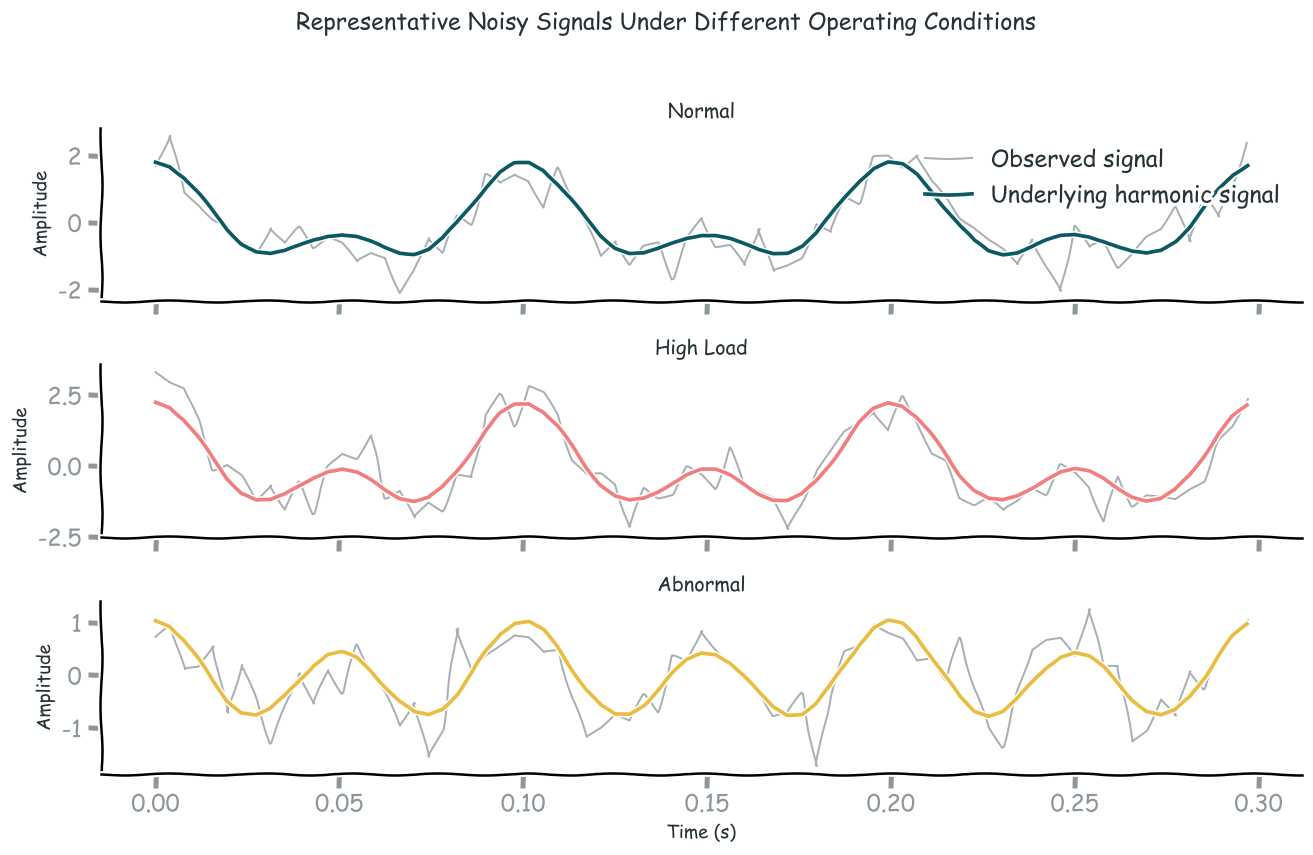

In [13]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(11, 7),
    sharex=True
)

# Show the first 0.3 seconds
time_mask = t <= 0.30

for k, ax in enumerate(axes):

    # Select one representative observation from each class
    idx = np.flatnonzero(labels_train == k)[0]

    observed = waveforms_train[idx]
    coefficients = true_coef_train[idx]

    # Reconstruct the underlying noise-free harmonic signal
    clean = Phi @ coefficients

    ax.plot(
        t[time_mask],
        observed[time_mask],
        color=GRAY,
        lw=1.2,
        alpha=0.75,
        label="Observed signal"
    )

    ax.plot(
        t[time_mask],
        clean[time_mask],
        color=CLASS_COLORS[k],
        lw=2.2,
        label="Underlying harmonic signal"
    )

    ax.set_title(CLASS_NAMES[k])
    ax.set_ylabel("Amplitude")

    ax.grid(alpha=0.15)

axes[0].legend(
    frameon=False,
    loc="upper right"
)

axes[-1].set_xlabel("Time (s)")

plt.suptitle(
    "Representative Noisy Signals Under Different Operating Conditions",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

#### Extract Features

In [7]:
def extract_features(waveforms, basis):
    """
    Estimate harmonic coefficients using least squares.

    Parameters
    ----------
    waveforms : ndarray, shape (N, T)
        Observed waveforms.

    basis : ndarray, shape (T, 2)
        Known harmonic basis matrix.

    Returns
    -------
    features : ndarray, shape (N, 2)
        Estimated harmonic coefficients.
    """

    coefficients, _, _, _ = np.linalg.lstsq(
        basis,
        waveforms.T,
        rcond=None
    )

    return coefficients.T


# Extract features from training and test observations
X_train = extract_features(waveforms_train, Phi)
X_test = extract_features(waveforms_test, Phi)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\nExample extracted feature vector:")
print(X_train[0])

print("\nCorresponding true coefficients:")
print(true_coef_train[0])

Training features: (360, 2)
Test features: (1500, 2)

Example extracted feature vector:
[1.09855383 0.68167769]

Corresponding true coefficients:
[1.07550668 0.73169995]


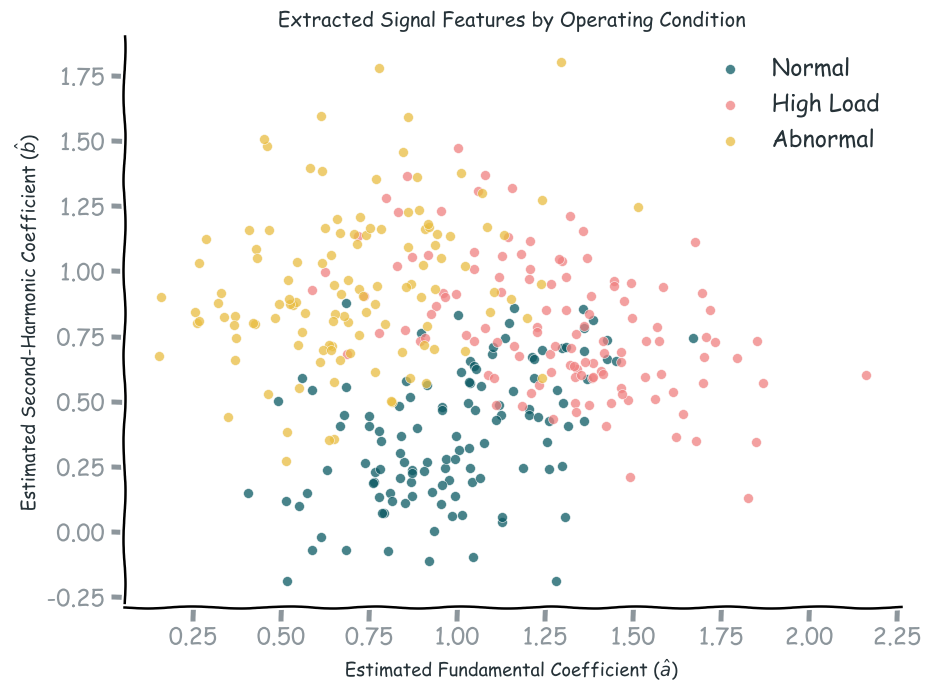

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

for k, (name, color) in enumerate(
    zip(CLASS_NAMES, CLASS_COLORS)
):

    mask = labels_train == k

    ax.scatter(
        X_train[mask, 0],
        X_train[mask, 1],
        s=35,
        color=color,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.4,
        label=name
    )

ax.set_xlabel(
    r"Estimated Fundamental Coefficient ($\hat{a}$)"
)

ax.set_ylabel(
    r"Estimated Second-Harmonic Coefficient ($\hat{b}$)"
)

ax.set_title(
    "Extracted Signal Features by Operating Condition"
)

ax.legend(frameon=False)

#ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

### 1.3 Understanding the Extracted Feature Distributions

We generated the underlying harmonic coefficients according to class-conditional Gaussian distributions.
However, the classifier does not observe those coefficients directly.
Instead, it receives their noisy least-squares estimates:
$$
\mathbf x_i=
\boldsymbol\beta_i+
\boldsymbol\eta_i,
$$
where
$$
\boldsymbol\eta_i=
(\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}
\boldsymbol\Phi^T\boldsymbol\epsilon_i.
$$
Under our assumptions,
$$
\boldsymbol\eta_i
\sim
\mathcal N(
\mathbf 0,
\boldsymbol\Sigma_\eta
),
$$
with
$$
\boxed{
\boldsymbol\Sigma_\eta=
\sigma_\epsilon^2
(\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}.
}
$$
This allows us to separate two sources of feature variability:

**1. Operating-condition variability**

The underlying harmonic coefficients vary between observations, according to the class-dependent covariance matrix $\boldsymbol\Sigma_k$.

**2. Measurement uncertainty**

The coefficients are estimated from noisy signals, introducing additional uncertainty described by $\boldsymbol\Sigma_\eta$.

The resulting class-conditional feature covariance is

$$
\boxed{
\boldsymbol\Sigma_k^{(x)}=
\boldsymbol\Sigma_k+\boldsymbol\Sigma_\eta.
}
$$

A Gaussian classifier must estimate the distributions of the **observed features**, not the unobservable true coefficients.
LDA assumes that the observed feature covariance is shared across classes.
QDA allows each class to have its own covariance matrix.
In our model, the measurement-noise contribution is common across classes, but the underlying coefficient covariance can differ.
Therefore, the overall feature covariances can also differ.

In [ ]:
feature_errors = X_train - true_coef_train

empirical_noise_cov = np.cov(
    feature_errors,
    rowvar=False
)

theoretical_noise_cov = (
    NOISE_STD**2
    * np.linalg.inv(Phi.T @ Phi)
)

print("Theoretical feature-noise covariance:")
print(theoretical_noise_cov)

print("\nEmpirical feature-noise covariance:")
print(empirical_noise_cov)

print("\nMean feature estimation error:")
print(feature_errors.mean(axis=0))

print("\nCovariance difference:")
print(empirical_noise_cov - theoretical_noise_cov)

Theoretical feature-noise covariance:
[[ 2.36328125e-03 -4.73501504e-20]
 [-4.73501504e-20  2.36328125e-03]]

Empirical feature-noise covariance:
[[ 0.00247937 -0.00013586]
 [-0.00013586  0.00264275]]

Mean feature estimation error:
[ 0.00090659 -0.00283226]

Covariance difference:
[[ 0.00011609 -0.00013586]
 [-0.00013586  0.00027947]]


### 1.4 Gaussian Class Models and Covariance Geometry


We have extracted a two-dimensional feature vector from each noisy signal:
$$
\mathbf{x}_i =
\begin{bmatrix}
\hat a_i\\
\hat b_i
\end{bmatrix}.
$$
Our objective is to predict the operating condition:
$$
C_i\in\{0,1,2\}.
$$
Under the assumptions of our signal-generation model, the extracted features follow class-conditional Gaussian distributions:
$$
\boxed{
\mathbf{x}\mid C=k
\sim
\mathcal N(\boldsymbol\mu_k,\boldsymbol\Sigma_k^{(x)})
}
$$
where
$$
\boldsymbol\Sigma_k^{(x)}=
\boldsymbol\Sigma_k+\boldsymbol\Sigma_\eta.
$$
The probability density function of a $d$-dimensional Gaussian distribution is
$$
p(\mathbf{x}\mid C=k)=
\frac{
\exp\left(
-\frac12
(\mathbf{x}-\boldsymbol\mu_k)^T
(\boldsymbol\Sigma_k^{(x)})^{-1}
(\mathbf{x}-\boldsymbol\mu_k)
\right)
}{
(2\pi)^{d/2}
|\boldsymbol\Sigma_k^{(x)}|^{1/2}
}.
$$

**What the Covariance Matrix Tells Us:**

The mean vector determines the center of the distribution.
The covariance matrix determines:
- **Spread:** How much the features vary.
- **Orientation:** Whether changes in the two features are correlated.
- **Shape:** Which directions exhibit greater or smaller variability.

For a two-dimensional Gaussian distribution, these properties can be visualized using covariance ellipses.
The eigenvectors of the covariance matrix determine the principal directions of the ellipse, while its eigenvalues determine the squared scales along those directions.

** Why Does This Matter for Classification?**

Consider two observations located at equal Euclidean distances from a Gaussian mean.
If one observation lies along a direction of large variance and the other lies along a direction of small variance, they need not have the same probability density.
The relevant distance is the **Mahalanobis distance**:
$$
\boxed{
d_{\Sigma}^{2}(\mathbf{x},\boldsymbol\mu)=
(\mathbf{x}-\boldsymbol\mu)^T
\boldsymbol\Sigma^{-1}
(\mathbf{x}-\boldsymbol\mu)
}
$$
This measures distance relative to the distribution's covariance structure.

In [ ]:
N_CLASSES = len(CLASS_NAMES)

theoretical_feature_covs = (
    COVS + theoretical_noise_cov[None, :, :]
)

empirical_means = np.zeros((N_CLASSES, 2))
empirical_covs = np.zeros((N_CLASSES, 2, 2))

for k in range(N_CLASSES):

    X_k = X_train[labels_train == k]

    empirical_means[k] = X_k.mean(axis=0)

    empirical_covs[k] = np.cov(
        X_k,
        rowvar=False
    )

for k, name in enumerate(CLASS_NAMES):

    print(f"\n{name}")
    print("-" * 40)

    print("Theoretical mean:")
    print(np.round(MEANS[k], 4))

    print("Empirical mean:")
    print(np.round(empirical_means[k], 4))

    print("\nTheoretical feature covariance:")
    print(np.round(theoretical_feature_covs[k], 4))

    print("Empirical feature covariance:")
    print(np.round(empirical_covs[k], 4))


Normal
----------------------------------------
Theoretical mean:
[1.   0.35]
Empirical mean:
[0.9875 0.3741]

Theoretical feature covariance:
[[0.0574 0.025 ]
 [0.025  0.0524]]
Empirical feature covariance:
[[0.0603 0.0282]
 [0.0282 0.0656]]

High Load
----------------------------------------
Theoretical mean:
[1.25 0.83]
Empirical mean:
[1.2892 0.7876]

Theoretical feature covariance:
[[ 0.0924 -0.045 ]
 [-0.045   0.0724]]
Empirical feature covariance:
[[ 0.0872 -0.0367]
 [-0.0367  0.0653]]

Abnormal
----------------------------------------
Theoretical mean:
[0.68 0.88]
Empirical mean:
[0.7055 0.9446]

Theoretical feature covariance:
[[0.0624 0.02  ]
 [0.02   0.0774]]
Empirical feature covariance:
[[0.0683 0.019 ]
 [0.019  0.0842]]


### 1.5 Visualizing Covariance Ellipses

A covariance ellipse represents a region of equal Mahalanobis distance from the mean.
For a two-dimensional Gaussian distribution, consider the region
$$
(\mathbf{x}-\boldsymbol\mu)^T
\boldsymbol\Sigma^{-1}
(\mathbf{x}-\boldsymbol\mu)
\leq c.
$$
The boundary is an ellipse when $\boldsymbol\Sigma$ is positive definite.
The eigenvectors of $\boldsymbol\Sigma$ determine its principal directions.
If the eigenvalues are $\lambda_1$ and $\lambda_2$, the corresponding semi-axis lengths are
$$
a=\sqrt{c\lambda_1},
\qquad
b=\sqrt{c\lambda_2}.
$$
For a two-dimensional Gaussian distribution,
$$
d_\Sigma^2(\mathbf{X},\boldsymbol\mu)
\sim \chi_2^2.
$$
Therefore, to construct an ellipse containing 90% of the probability mass, we choose
$$
c=\chi_{2,0.90}^2.
$$
The resulting ellipse is a **90% probability region under the Gaussian model**.

This does not mean that exactly 90% of a finite sample must lie inside the ellipse.

In [ ]:
from matplotlib.patches import Ellipse
from scipy.stats import chi2


def add_covariance_ellipse(
    ax,
    mean,
    cov,
    color,
    probability=0.90,
    linestyle="-",
    linewidth=2.0,
):


    mean = np.asarray(mean)
    cov = np.asarray(cov)

    if not 0 < probability < 1:
        raise ValueError("probability must be between 0 and 1.")

    # Eigenvalue decomposition
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    if np.any(eigenvalues <= 0):
        raise ValueError("Covariance must be positive definite.")

    order = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(
            eigenvectors[1, 0],
            eigenvectors[0, 0]
        )
    )

    # Chi-square scaling for the desired probability mass
    scale = np.sqrt(
        chi2.ppf(probability, df=2)
    )

    width = 2 * scale * np.sqrt(eigenvalues[0])
    height = 2 * scale * np.sqrt(eigenvalues[1])

    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        edgecolor=color,
        facecolor="none",
        linestyle=linestyle,
        linewidth=linewidth
    )

    ax.add_patch(ellipse)

    return ellipse

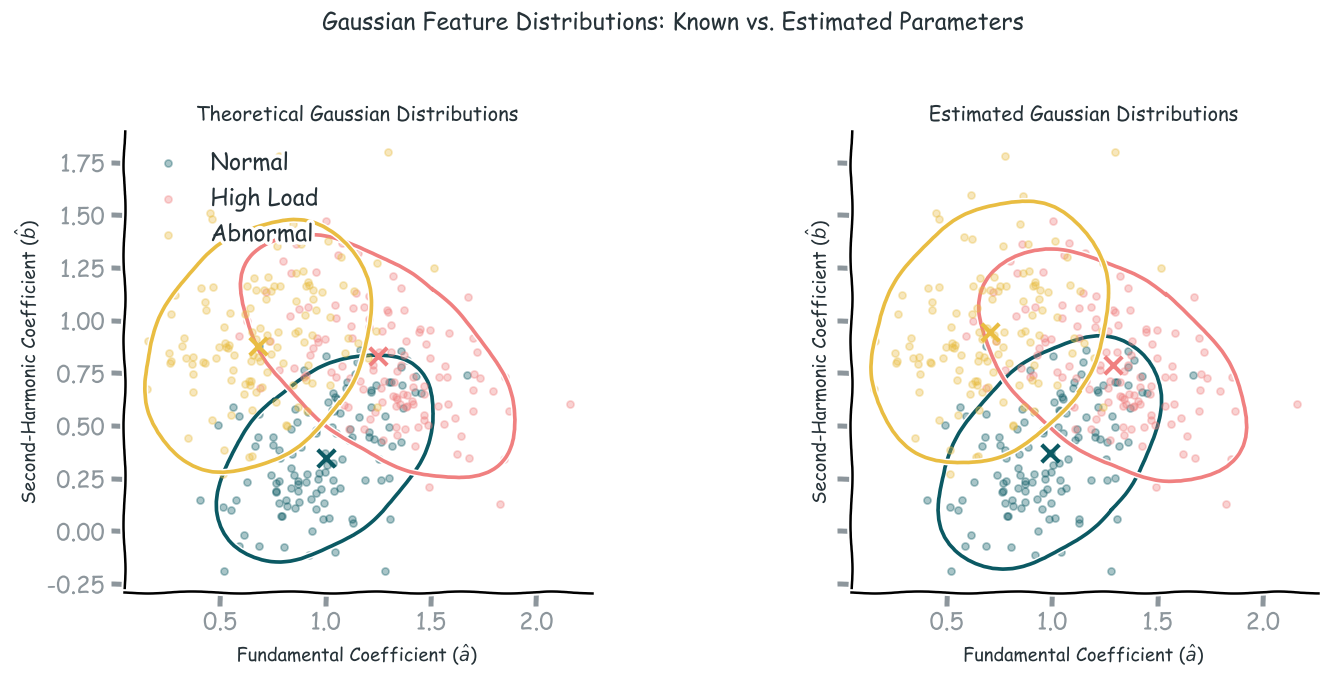

In [17]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharex=True,
    sharey=True
)

# Compare known generating parameters and empirical estimates
settings = [
    (
        "Theoretical Gaussian Distributions",
        MEANS,
        theoretical_feature_covs
    ),
    (
        "Estimated Gaussian Distributions",
        empirical_means,
        empirical_covs
    )
]

for ax, (title, means, covs) in zip(axes, settings):

    for k, (name, color) in enumerate(
        zip(CLASS_NAMES, CLASS_COLORS)
    ):

        mask = labels_train == k

        # Training observations
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            s=18,
            color=color,
            alpha=0.35,
            label=name
        )

        # Gaussian covariance ellipse
        add_covariance_ellipse(
            ax,
            mean=means[k],
            cov=covs[k],
            color=color,
            probability=0.90,
            linewidth=2.2
        )

        # Component mean
        ax.scatter(
            means[k, 0],
            means[k, 1],
            marker="x",
            s=110,
            color=color,
            linewidths=2.5
        )

    ax.set_title(title)

    ax.set_xlabel(
        r"Fundamental Coefficient ($\hat{a}$)"
    )

    ax.set_ylabel(
        r"Second-Harmonic Coefficient ($\hat{b}$)"
    )

    ax.set_aspect("equal", adjustable="box")
    #ax.grid(alpha=0.15)

axes[0].legend(
    frameon=False,
    loc="upper left"
)

plt.suptitle(
    "Gaussian Feature Distributions: Known vs. Estimated Parameters",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()

### 1.6 Linear and Quadratic Discriminant Analysis

We now want to predict the operating condition of a new observation.
A Gaussian generative classifier uses Bayes' rule:
$$
P(C=k\mid\mathbf{x})=
\frac{
p(\mathbf{x}\mid C=k)\pi_k
}{
\sum_{j=1}^{K}
p(\mathbf{x}\mid C=j)\pi_j
},
$$
where
$$
\pi_k=P(C=k)
$$
is the class prior probability.  
Under 0–1 classification loss, the optimal Bayesian decision selects the class with the largest posterior probability:
$$
\boxed{
\hat C(\mathbf{x})=
\arg\max_k P(C=k\mid\mathbf{x})
}
$$
For Gaussian class-conditional distributions, the discriminant function can be written as

$$
g_k(\mathbf{x})=
-\frac12\log|\boldsymbol\Sigma_k|
-\frac12
(\mathbf{x}-\boldsymbol\mu_k)^T
\boldsymbol\Sigma_k^{-1}
(\mathbf{x}-\boldsymbol\mu_k)
+\log\pi_k.
$$
Terms common to all classes have been omitted because they do not affect the decision.

The classifier predicts
$$
\hat C(\mathbf{x})=
\arg\max_k g_k(\mathbf{x}).
$$

#### Linear Discriminant Analysis (LDA)

LDA assumes that all classes share one covariance matrix:
$$
\boxed{
\boldsymbol\Sigma_1=
\boldsymbol\Sigma_2=
\cdots=
\boldsymbol\Sigma_K=
\boldsymbol\Sigma.
}
$$
Under this assumption, the quadratic terms in the Gaussian discriminants cancel when comparing classes.
The resulting pairwise decision boundaries are linear.

**Advantages**

- Fewer covariance parameters need to be estimated.
- Can perform well with relatively limited training data.
- Appropriate when class covariance structures are sufficiently similar.

**Limitation**

The shared-covariance assumption can introduce model mismatch when the true class covariances differ.

#### Quadratic Discriminant Analysis (QDA)

QDA allows each class to have its own covariance matrix:
$$
\boxed{
\boldsymbol\Sigma_k
\text{ can differ across classes.}
}
$$
The quadratic terms no longer cancel in general, producing quadratic decision boundaries.

**Advantages**

- More flexible class-conditional distributions.
- Can represent differences in class covariance structures.

**Limitations**

- Requires estimating more covariance parameters.
- Can be sensitive to limited training data.
- May overfit when the additional flexibility is not supported by enough observations.

#### Connection to Our Dataset

Our three operating conditions have different covariance matrices.
Therefore, QDA is better aligned with the known data-generating model.
However, this does not guarantee that QDA will outperform LDA on every finite training and test sample.
We will evaluate both models rather than assuming the outcome.

In [ ]:
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

from sklearn.metrics import (
    accuracy_score,
    log_loss
)


# the two Gaussian classifiers
lda = LinearDiscriminantAnalysis(
    solver="svd",
    store_covariance=True
)

qda = QuadraticDiscriminantAnalysis(
    reg_param=0.0,
    store_covariance=True
)

# Fit using training observations only
lda.fit(X_train, labels_train)
qda.fit(X_train, labels_train)

models = {
    "LDA": lda,
    "QDA": qda
}

print("Both Gaussian classifiers have been fitted.")
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Both Gaussian classifiers have been fitted.
Training observations: 360
Test observations: 1500


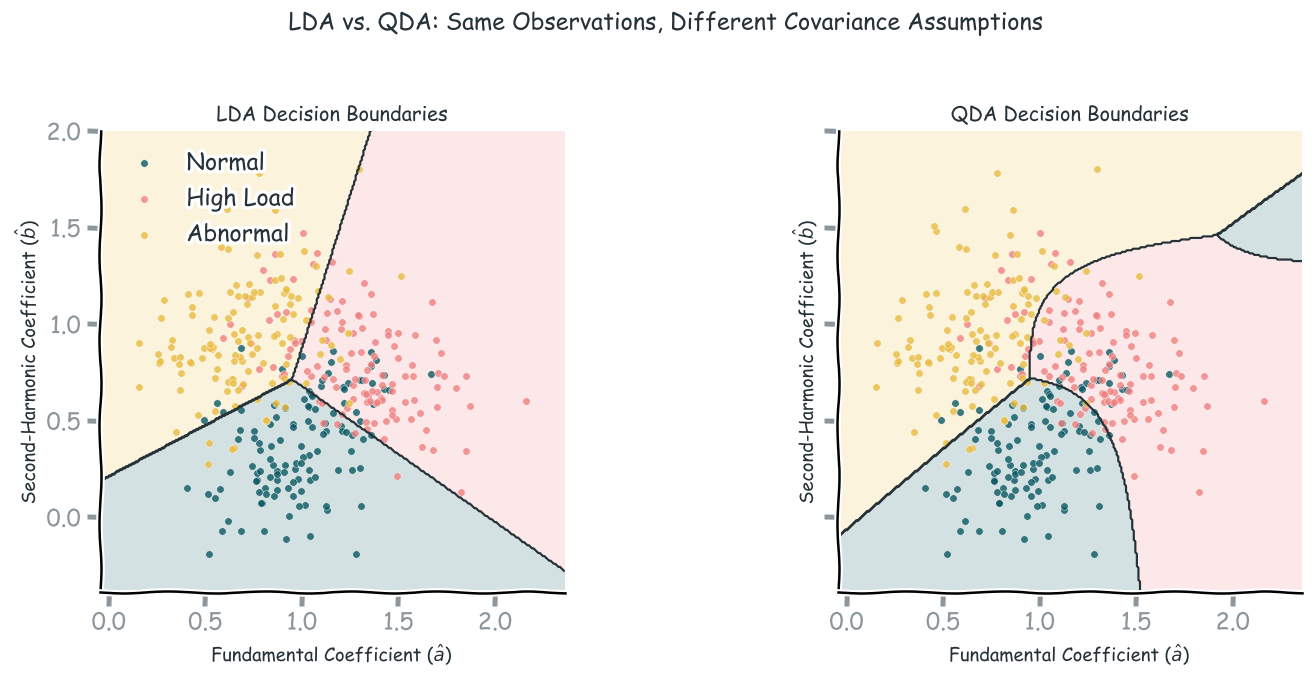

In [ ]:
padding = 0.20

x_min = X_train[:, 0].min() - padding
x_max = X_train[:, 0].max() + padding

y_min = X_train[:, 1].min() - padding
y_max = X_train[:, 1].max() + padding

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharex=True,
    sharey=True
)

for ax, (name, model) in zip(axes, models.items()):

    grid_predictions = model.predict(
        grid_points
    ).reshape(xx.shape)

    # Decision regions
    ax.contourf(
        xx,
        yy,
        grid_predictions,
        levels=np.arange(N_CLASSES + 1) - 0.5,
        colors=CLASS_COLORS,
        alpha=0.18
    )

    # Decision boundaries
    ax.contour(
        xx,
        yy,
        grid_predictions,
        levels=np.arange(N_CLASSES - 1) + 0.5,
        colors=DARK,
        linewidths=1.3
    )

    # Training observations
    for k, (class_name, color) in enumerate(
        zip(CLASS_NAMES, CLASS_COLORS)
    ):

        mask = labels_train == k

        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            s=20,
            color=color,
            alpha=0.80,
            edgecolors="white",
            linewidths=0.3,
            label=class_name
        )

    ax.set_title(f"{name} Decision Boundaries")

    ax.set_xlabel(
        r"Fundamental Coefficient ($\hat{a}$)"
    )

    ax.set_ylabel(
        r"Second-Harmonic Coefficient ($\hat{b}$)"
    )

    ax.set_aspect("equal", adjustable="box")
    #ax.grid(alpha=0.10)

axes[0].legend(
    frameon=False,
    loc="upper left"
)

plt.suptitle(
    "LDA vs. QDA: Same Observations, Different Covariance Assumptions",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()

### 1.7 Evaluating Classification Performance

A more flexible decision boundary does not necessarily imply better predictions on unseen observations.
We will compare LDA and QDA using both training and independent test observations.
Two evaluation metrics will be considered.

#### Classification Accuracy

Accuracy measures the proportion of correctly classified observations:
$$
\boxed{
\mathrm{Accuracy}=
\frac{1}{N}
\sum_{i=1}^{N}
\mathbb{I}(\hat C_i=C_i)
}
$$
Accuracy evaluates the final class decisions.
However, it does not indicate whether the predicted probabilities are reliable.

#### Multiclass Log Loss

For $K$ classes, the multiclass log loss is
$$
\boxed{
\mathcal L_{\mathrm{log}}=
-\frac{1}{N}
\sum_{i=1}^{N}
\sum_{k=1}^{K}
\mathbb{I}(C_i=k)
\log\hat p_{ik}
}
$$
where
$$
\hat p_{ik}=P(C_i=k\mid\mathbf{x}_i)
$$
is the probability predicted by the classifier.
Lower log loss indicates better probabilistic predictions under this scoring rule.
Log loss penalizes confident incorrect predictions more heavily than uncertain incorrect predictions.

 **Why Use Both Metrics?**

Two classifiers can have similar accuracy but different probability estimates.
For example, suppose the correct class is $C=1$.
Classifier A predicts:
$$
(0.05,\ 0.90,\ 0.05)
$$
Classifier B predicts:
$$
(0.30,\ 0.40,\ 0.30).
$$
Both predict the correct class, but their confidence differs substantially.
Conversely, an overconfident incorrect prediction can produce a large log-loss penalty.

#### Evaluation Protocol

We will:
1. Fit both classifiers using only the training observations.
2. Evaluate their performance on the training set.
3. Evaluate their performance on the independent test set.
4. Compare accuracy and log loss.


In [20]:
# Evaluate both classifiers
results = {}

for name, model in models.items():

    # Training predictions
    train_pred = model.predict(X_train)
    train_proba = model.predict_proba(X_train)

    # Test predictions
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)

    results[name] = {
        "train_accuracy": accuracy_score(
            labels_train,
            train_pred
        ),
        "test_accuracy": accuracy_score(
            labels_test,
            test_pred
        ),
        "train_log_loss": log_loss(
            labels_train,
            train_proba,
            labels=np.arange(N_CLASSES)
        ),
        "test_log_loss": log_loss(
            labels_test,
            test_proba,
            labels=np.arange(N_CLASSES)
        )
    }


# Display results
print(
    f"{'Model':<10}"
    f"{'Train Acc.':>12}"
    f"{'Test Acc.':>12}"
    f"{'Train Loss':>14}"
    f"{'Test Loss':>14}"
)

print("-" * 62)

for name, metrics in results.items():

    print(
        f"{name:<10}"
        f"{metrics['train_accuracy']:>12.4f}"
        f"{metrics['test_accuracy']:>12.4f}"
        f"{metrics['train_log_loss']:>14.4f}"
        f"{metrics['test_log_loss']:>14.4f}"
    )

Model       Train Acc.   Test Acc.    Train Loss     Test Loss
--------------------------------------------------------------
LDA             0.7750      0.7853        0.5406        0.5381
QDA             0.7889      0.7980        0.4868        0.4518


# Part II: Learning Hidden Structure

## Experiment 2: Discovering Hidden Operating Conditions with Gaussian Mixture Models

Suppose we observe the feature vectors extracted from a collection of vibration signals, but we do not know which operating condition generated each observation.
Our dataset now contains only
$$
\boxed{
\mathcal D = \{\mathbf{x}_1,\mathbf{x}_2,\ldots,\mathbf{x}_N\}.
}
$$
The generating component assignments are hidden.
We want to investigate whether a probabilistic model can discover the statistical structure of the observations without using their labels.

In this experiment, we will:

1. Remove the labels from our previous signal-feature dataset.
2. Model the observations using a Gaussian Mixture Model (GMM).
3. Understand probabilistic component assignments, called responsibilities.
4. Implement the Expectation–Maximization (EM) algorithm.
5. Visualize how the Gaussian components evolve during learning.
6. Examine the observed-data log-likelihood during EM iterations.

### 2.1 From Labeled Observations to Hidden Variables

In supervised learning, our training dataset contains observations and their corresponding labels:
$$
\mathcal D_{\mathrm{sup}}=
\{(\mathbf{x}_n,c_n)\}_{n=1}^{N}.
$$
During Experiment 1, we used these labels to estimate a Gaussian distribution for each operating condition.
Now consider a different learning setting.
We observe the same feature vectors, but their labels are not provided to the learning algorithm:
$$
\boxed{
\mathcal D_{\mathrm{unsup}}=
\{\mathbf{x}_n\}_{n=1}^{N}.
}
$$
To describe the unknown generating structure, we introduce a latent variable
$$
Z_n\in\{1,\ldots,K\},
$$
where $Z_n=k$ means that observation $\mathbf{x}_n$ was generated by mixture component $k$.
The variable $Z_n$ is **latent** because its value is not observed.

#### Classes vs. Mixture Components

In supervised classification, class labels often have a specific physical or application-dependent meaning.
For example:
- Normal operation.
- High-load operation.
- Abnormal operation.

In a Gaussian mixture model, however, component indices are initially only statistical labels.
A component does not automatically correspond to a particular operating condition.
Even if the data were generated from three physical conditions, a fitted model with three Gaussian components is not guaranteed to recover those conditions exactly.
We must distinguish:

**Physical classes:** Categories defined by the application or data-generating process.

**Statistical components:** Distributions estimated by the mixture model.

The relationship between the two must be evaluated rather than assumed.

#### Experimental Setting

We will reuse the feature observations from Experiment 1.
However, the GMM will receive only the feature matrix, without the generating class labels.
Because this is a controlled simulation, we know that the data were generated using three Gaussian populations.
We will initially specify $K=3$ to investigate how EM learns the mixture parameters.
Choosing the number of components when it is unknown will be investigated in the optional notebook sections.

In [ ]:
rng_gmm = np.random.default_rng(BASE_SEED + 303)

# Shuffle the observations to remove their original class-wise ordering.
shuffle_idx = rng_gmm.permutation(len(X_train))

X_unlabeled = X_train[shuffle_idx].copy()

N, D = X_unlabeled.shape

print("Unlabeled dataset shape:", X_unlabeled.shape)
print("Number of observations:", N)
print("Feature dimension:", D)
print("\nClass labels are not used during GMM fitting.")

Unlabeled dataset shape: (360, 2)
Number of observations: 360
Feature dimension: 2

Class labels are not used during GMM fitting.


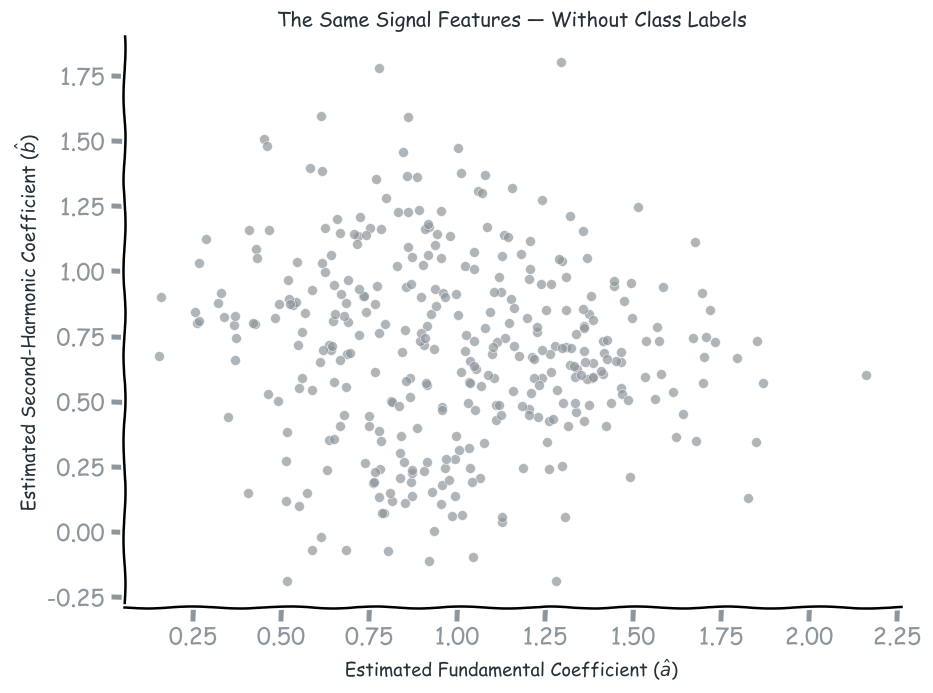

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    X_unlabeled[:, 0],
    X_unlabeled[:, 1],
    s=35,
    color=GRAY,
    alpha=0.70,
    edgecolors="white",
    linewidths=0.4
)

ax.set_xlabel(
    r"Estimated Fundamental Coefficient ($\hat{a}$)"
)

ax.set_ylabel(
    r"Estimated Second-Harmonic Coefficient ($\hat{b}$)"
)

ax.set_title(
    "The Same Signal Features — Without Class Labels"
)

#ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

### 2.2 Gaussian Mixture Models

A Gaussian Mixture Model represents a probability distribution as a weighted combination of Gaussian components.
For a $K$-component mixture,
$$
\boxed{
p(\mathbf{x}\mid\boldsymbol\theta)=
\sum_{k=1}^{K}
\pi_k
\mathcal N(
\mathbf{x};
\boldsymbol\mu_k,
\boldsymbol\Sigma_k
)
}
$$
where:
- $K$ is the number of Gaussian components.
- $\pi_k$ is the mixing weight of component $k$.
- $\boldsymbol\mu_k$ is its mean vector.
- $\boldsymbol\Sigma_k$ is its covariance matrix.
- $\boldsymbol\theta$ represents all mixture parameters.

The mixing weights satisfy
$$
\pi_k\geq 0,
\qquad
\sum_{k=1}^{K}\pi_k=1.
$$
A Gaussian mixture can be understood through a two-stage generative process.

**Step 1: Select a hidden component**
$$
Z_n\sim\operatorname{Categorical}(\pi_1,\ldots,\pi_K).
$$

**Step 2: Generate an observation**
$$
\mathbf{x}_n\mid Z_n=k
\sim
\mathcal N(
\boldsymbol\mu_k,
\boldsymbol\Sigma_k
).
$$
The component assignment determines which Gaussian distribution generates the observation.
However, when we observe $\mathbf{x}_n$, the generating component $Z_n$ is unknown.

#### The Learning Problem
We want to estimate
$$
\boldsymbol\theta=
\{\pi_k,\boldsymbol\mu_k,\boldsymbol\Sigma_k\}_{k=1}^{K}
$$
using only the observed features.
If the component assignments were known, estimating the component parameters would be straightforward.
Without the assignments, we must jointly reason about the hidden components and the distribution parameters.
This motivates the Expectation–Maximization algorithm.

> **An Important Modeling Assumption**  
> A GMM assumes that the observed probability distribution can be represented using Gaussian components. This does not mean that every physical operating condition must correspond to exactly one Gaussian component. A complex physical condition may require several components, and overlapping conditions may not be perfectly recoverable from the available features. The mixture model describes **statistical structure**, which must be interpreted carefully.

### 2.3 Responsibilities: Probabilistic Component Assignments

Suppose we have a current estimate of the mixture parameters:
$$
\boldsymbol\theta=
\{\pi_k,\boldsymbol\mu_k,\boldsymbol\Sigma_k\}_{k=1}^{K}.
$$
For an observed feature vector $\mathbf{x}_n$, we want to estimate which Gaussian component generated it.
Using Bayes' rule,
$$
P(Z_n=k\mid\mathbf{x}_n,\boldsymbol\theta)=
\frac{
p(\mathbf{x}_n\mid Z_n=k,\boldsymbol\theta)
P(Z_n=k\mid\boldsymbol\theta)
}{
p(\mathbf{x}_n\mid\boldsymbol\theta)
}.
$$
Substituting the GMM distributions gives
$$
\boxed{
r_{nk}=
\frac{
\pi_k
\mathcal N(
\mathbf{x}_n;
\boldsymbol\mu_k,
\boldsymbol\Sigma_k
)
}{
\sum_{j=1}^{K}
\pi_j
\mathcal N(
\mathbf{x}_n;
\boldsymbol\mu_j,
\boldsymbol\Sigma_j
)
}
}
$$
The quantity
$$
\boxed{
r_{nk}=
P(Z_n=k\mid\mathbf{x}_n,\boldsymbol\theta)
}
$$
is called the **responsibility** of component $k$ for observation $n$.
Responsibilities satisfy
$$
0\leq r_{nk}\leq1,
\qquad
\sum_{k=1}^{K}r_{nk}=1.
$$

#### Hard vs. Soft Assignments

In hard clustering, an observation is assigned to one component:
$$
\hat z_n=
\arg\max_k r_{nk}.
$$
In soft clustering, we retain the entire vector of responsibilities:
$$
\mathbf r_n=
[r_{n1},r_{n2},\ldots,r_{nK}].
$$
For example, an observation might have responsibilities
$$
\mathbf r_n=[0.55,\ 0.40,\ 0.05].
$$
This indicates that the first component has the highest posterior probability, but the second component also provides a plausible explanation.

**Why Are Responsibilities Useful?**

Rather than assigning an observation entirely to one component, we can let it influence several components with different weights.
This is the key idea behind the M-step of EM.
The model will use these responsibilities to compute weighted estimates of the component parameters.

> **Note:**
> Responsibilities depend on the **current estimated parameters**. They are not fixed properties of the observations. As the mixture parameters change during EM, the responsibilities can change as well. This creates the iterative relationship:
> $$
> \boxed{
> \text{Parameters}
> \longrightarrow
> \text{Responsibilities}
> \longrightarrow
> \text{Updated Parameters}
> }
> $$

In [ ]:
# Initialize a 3-component Gaussian Mixture Model
K = 3

weights_init = np.full(K, 1.0 / K)

initial_indices = rng_gmm.choice(
    N,
    size=K,
    replace=False
)

means_init = X_unlabeled[initial_indices].copy()

global_cov = np.cov(
    X_unlabeled,
    rowvar=False
)

covs_init = np.repeat(
    global_cov[None, :, :],
    K,
    axis=0
)

# Basic validity checks
assert np.isclose(weights_init.sum(), 1.0)
assert np.all(weights_init > 0)
assert np.all(np.linalg.eigvalsh(covs_init) > 0)

print("Initial mixing weights:")
print(np.round(weights_init, 4))

print("\nInitial component means:")
print(np.round(means_init, 4))

print("\nInitial covariance matrices:")
print(np.round(covs_init, 4))

Initial mixing weights:
[0.3333 0.3333 0.3333]

Initial component means:
[[0.5605 0.5905]
 [0.5893 0.546 ]
 [0.9342 0.7019]]

Initial covariance matrices:
[[[ 0.1285 -0.0107]
  [-0.0107  0.1293]]

 [[ 0.1285 -0.0107]
  [-0.0107  0.1293]]

 [[ 0.1285 -0.0107]
  [-0.0107  0.1293]]]


#### E-Step Implementation

In [ ]:
from scipy.stats import multivariate_normal
from scipy.special import logsumexp


def gmm_e_step(X, weights, means, covariances):
    N, D = X.shape
    K = len(weights)

    log_joint = np.empty((N, K))

    # Compute log[p(x_n | z_n=k) * pi_k]
    for k in range(K):

        log_joint[:, k] = (
            np.log(weights[k])
            +
            multivariate_normal.logpdf(
                X,
                mean=means[k],
                cov=covariances[k],
                allow_singular=False
            )
        )

    log_marginal = logsumexp(
        log_joint,
        axis=1
    )

    responsibilities = np.exp(
        log_joint - log_marginal[:, None]
    )

    log_likelihood = np.sum(log_marginal)

    return responsibilities, log_likelihood

#### Calculate Initial Responsibilities

In [26]:
# Compute responsibilities using the initial parameters
R_init, initial_log_likelihood = gmm_e_step(
    X_unlabeled,
    weights_init,
    means_init,
    covs_init
)

print("Responsibility matrix shape:", R_init.shape)

print("\nFirst five responsibility vectors:")
print(np.round(R_init[:5], 4))

print("\nRow sums (first five observations):")
print(np.round(R_init[:5].sum(axis=1), 8))

print("\nMinimum responsibility:", R_init.min())
print("Maximum responsibility:", R_init.max())

print("\nInitial log-likelihood:")
print(f"{initial_log_likelihood:.4f}")

# Numerical checks
assert R_init.shape == (N, K)
assert np.all(np.isfinite(R_init))
assert np.all(R_init >= 0)
assert np.allclose(R_init.sum(axis=1), 1.0)

print("\nE-step numerical checks passed.")

Responsibility matrix shape: (360, 3)

First five responsibility vectors:
[[0.2439 0.2899 0.4663]
 [0.1595 0.1748 0.6657]
 [0.1768 0.1862 0.637 ]
 [0.1081 0.1259 0.7659]
 [0.384  0.4173 0.1987]]

Row sums (first five observations):
[1. 1. 1. 1. 1.]

Minimum responsibility: 0.014597711570179124
Maximum responsibility: 0.9656935032727936

Initial log-likelihood:
-399.2363

E-step numerical checks passed.


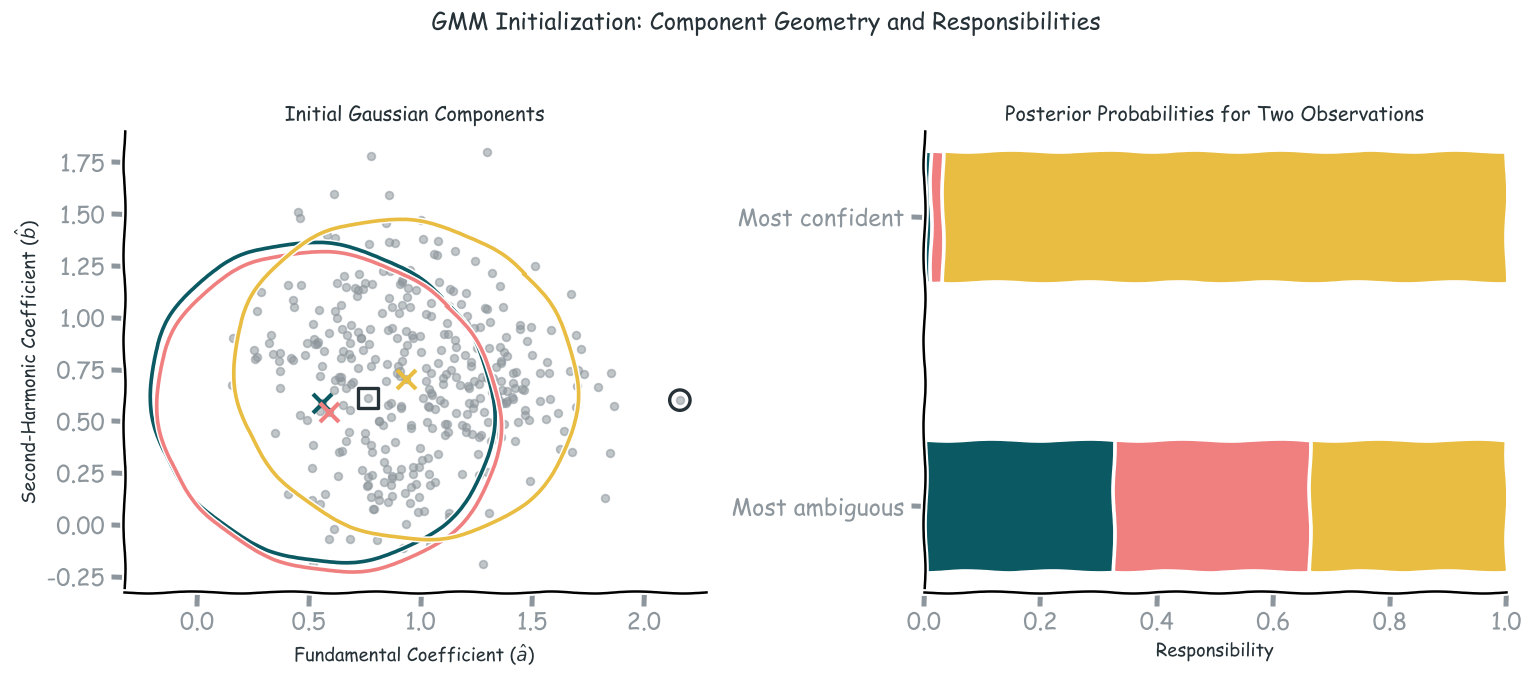


Most confident observation
Index: 47
Features: [2.1608 0.6023]
Responsibilities: [0.0146 0.0197 0.9657]

Most ambiguous observation
Index: 281
Features: [0.7658 0.613 ]
Responsibilities: [0.3288 0.3363 0.3349]


In [ ]:
confidence = R_init.max(axis=1)

idx_confident = np.argmax(confidence)
idx_ambiguous = np.argmin(confidence)

selected_indices = [
    idx_confident,
    idx_ambiguous
]

selected_names = [
    "Most confident",
    "Most ambiguous"
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5)
)

# Left: Initial Gaussian components
ax = axes[0]

ax.scatter(
    X_unlabeled[:, 0],
    X_unlabeled[:, 1],
    s=22,
    color=GRAY,
    alpha=0.55,
    label="Unlabeled observations"
)

for k in range(K):

    color = CLASS_COLORS[k]

    add_covariance_ellipse(
        ax,
        means_init[k],
        covs_init[k],
        color=color,
        probability=0.90,
        linewidth=2.2
    )

    ax.scatter(
        means_init[k, 0],
        means_init[k, 1],
        marker="x",
        s=130,
        linewidths=2.5,
        color=color
    )

for idx, marker in zip(
    selected_indices,
    ["o", "s"]
):

    ax.scatter(
        X_unlabeled[idx, 0],
        X_unlabeled[idx, 1],
        marker=marker,
        s=150,
        facecolors="none",
        edgecolors=DARK,
        linewidths=2.0
    )

ax.set_title("Initial Gaussian Components")

ax.set_xlabel(r"Fundamental Coefficient ($\hat{a}$)")
ax.set_ylabel(r"Second-Harmonic Coefficient ($\hat{b}$)")

#ax.grid(alpha=0.15)


# Right: Responsibility vectors
ax = axes[1]

for row, idx in enumerate(selected_indices):

    left = 0.0

    for k in range(K):

        value = R_init[idx, k]

        ax.barh(
            row,
            value,
            left=left,
            color=CLASS_COLORS[k],
            height=0.45,
            edgecolor="white",
            linewidth=1.0
        )

        left += value

ax.set_xlim(0, 1)

ax.set_yticks(
    [0, 1],
    selected_names
)

ax.invert_yaxis()

ax.set_xlabel("Responsibility")

ax.set_title(
    "Posterior Probabilities for Two Observations"
)

#ax.grid(
    #axis="x",
    #alpha=0.15
#)

plt.suptitle(
    "GMM Initialization: Component Geometry and Responsibilities",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()


# Print exact responsibility values
for name, idx in zip(selected_names, selected_indices):

    print(f"\n{name} observation")
    print("Index:", idx)
    print("Features:", np.round(X_unlabeled[idx], 4))
    print("Responsibilities:", np.round(R_init[idx], 4))

### 2.4 The M-Step: Updating the Gaussian Parameters

In the previous section, we implemented the **E-step** of the Expectation–Maximization algorithm.
Given the current mixture parameters,
$$
\boldsymbol{\theta}^{(t)}=
\left\{
\pi_k^{(t)},
\boldsymbol{\mu}_k^{(t)},
\boldsymbol{\Sigma}_k^{(t)}
\right\}_{k=1}^{K},
$$
the E-step estimates the posterior responsibilities:
$$
r_{nk}^{(t)}=
P\left(
Z_n=k
\mid
\mathbf{x}_n,\boldsymbol{\theta}^{(t)}
\right).
$$
These responsibilities tell us how strongly each component explains each observation.
However, the E-step does **not** update the model parameters.
The next question is:

> How can we use the estimated responsibilities to improve the Gaussian mixture model?

This is the purpose of the **Maximization step (M-step)**.

#### 1. Effective Number of Observations

First, define
$$
\boxed{
N_k=
\sum_{n=1}^{N}r_{nk}.
}
$$
The quantity $N_k$ is called the **effective number of observations** assigned to component $k$.
Unlike hard clustering, $N_k$ does not need to be an integer.
For example, suppose three observations have responsibilities for component 1 equal to
$$
[0.9,\ 0.6,\ 0.2].
$$
Then
$$
N_1=0.9+0.6+0.2=1.7.
$$
Although we have three observations, their combined contribution to this component is equivalent to an effective weight of 1.7 observations.
Since every observation's responsibilities sum to one,
$$
\boxed{
\sum_{k=1}^{K}N_k=N.
}
$$

#### 2. Updating the Mixing Weights

The mixing weight of component $k$ is updated as
$$
\boxed{
\pi_k^{(t+1)}=
\frac{N_k}{N}.
}
$$
Thus, a component receiving more total responsibility obtains a larger mixing weight.
The updated weights automatically satisfy
$$
\sum_{k=1}^{K}\pi_k^{(t+1)}=1.
$$

#### 3. Updating the Component Means

The updated mean is a responsibility-weighted average:
$$
\boxed{
\boldsymbol{\mu}_k^{(t+1)}=
\frac{1}{N_k}
\sum_{n=1}^{N}
r_{nk}^{(t)}\mathbf{x}_n.
}
$$
Compare this with the ordinary sample mean:
$$
\bar{\mathbf{x}}=
\frac{1}{N}
\sum_{n=1}^{N}\mathbf{x}_n.
$$
The difference is that each observation contributes according to its responsibility.
An observation with high responsibility for component $k$ has a stronger influence on that component's mean.
An observation with very low responsibility contributes very little.

**Geometric interpretation:** Each Gaussian mean moves toward observations that its component is responsible for explaining.

#### 4. Updating the Covariance Matrices

The updated covariance matrix is
$$
\boxed{
\boldsymbol{\Sigma}_k^{(t+1)}=
\frac{1}{N_k}
\sum_{n=1}^{N}
r_{nk}^{(t)}
\left(
\mathbf{x}_n-\boldsymbol{\mu}_k^{(t+1)}
\right)
\left(
\mathbf{x}_n-\boldsymbol{\mu}_k^{(t+1)}
\right)^T.
}
$$
This is a responsibility-weighted covariance estimate.
Notice that the equation uses the **updated component mean**, not the previous mean.
The covariance determines how the component spreads and changes orientation to better explain its assigned observations.
Unlike the conventional unbiased sample covariance, the M-step uses the maximum-likelihood normalization $N_k$, not $N_k-1$.

#### 5. Putting Everything Together

The M-step updates all three groups of parameters:

| Parameter | Update | Interpretation |
|---|---|---|
| Mixing weight | $\pi_k=N_k/N$ | How much of the population does the component explain? |
| Mean | $\boldsymbol{\mu}_k=\sum_n r_{nk}\mathbf{x}_n/N_k$ | Where is the component centered? |
| Covariance | Weighted covariance | How are the component's observations distributed? |

These updates maximize the expected complete-data log-likelihood with the E-step responsibilities held fixed.

For now, the key idea is:
$$
\boxed{
\text{Responsibilities}
\longrightarrow
\text{Weighted Parameter Estimates}
}
$$
After the M-step, the updated parameters can be used to compute new responsibilities.
This creates the iterative EM algorithm.

In [ ]:
def gmm_m_step(X, responsibilities):

    N, D = X.shape
    K = responsibilities.shape[1]

    # 1. Effective number of observations per component
    N_k = responsibilities.sum(axis=0)

    if np.any(N_k <= 1e-10):
        raise ValueError(
            "At least one component has negligible effective weight."
        )

    # 2. Update mixing weights
    weights = N_k / N

    # 3. Update component means
    means = (
        responsibilities.T @ X
    ) / N_k[:, None]

    # 4. Update covariance matrices
    covariances = np.empty((K, D, D))

    for k in range(K):

        centered = X - means[k]

        covariances[k] = (
            (responsibilities[:, k, None] * centered).T
            @ centered
        ) / N_k[k]

        covariances[k] = 0.5 * (
            covariances[k] + covariances[k].T
        )

    return weights, means, covariances

In [31]:
R_init, initial_log_likelihood = gmm_e_step(
    X_unlabeled,
    weights_init,
    means_init,
    covs_init
)

In [ ]:

weights_1, means_1, covs_1 = gmm_m_step(
    X_unlabeled,
    R_init
)

N_k = R_init.sum(axis=0)

print("Effective component sample sizes:")
print(np.round(N_k, 4))

print("\nUpdated mixing weights:")
print(np.round(weights_1, 4))

print("\nUpdated component means:")
print(np.round(means_1, 4))

print("\nUpdated covariance matrices:")
print(np.round(covs_1, 4))


# Verify the updated parameters
assert np.all(weights_1 > 0)

assert np.isclose(
    weights_1.sum(),
    1.0
)

assert np.all(
    np.linalg.eigvalsh(covs_1) > 0
)

print("\nM-step parameter checks passed.")


# Evaluate the updated mixture model
R_1, log_likelihood_1 = gmm_e_step(
    X_unlabeled,
    weights_1,
    means_1,
    covs_1
)

print("\nObserved-data log-likelihood:")
print(f"Before M-step: {initial_log_likelihood:.6f}")
print(f"After M-step:  {log_likelihood_1:.6f}")

improvement = (
    log_likelihood_1 - initial_log_likelihood
)

print(f"\nLog-likelihood improvement: {improvement:.6f}")

assert log_likelihood_1 >= initial_log_likelihood - 1e-8

print("\nLikelihood monotonicity check passed.")

Effective component sample sizes:
[ 85.8262  88.2333 185.9405]

Updated mixing weights:
[0.2384 0.2451 0.5165]

Updated component means:
[[0.8297 0.6679]
 [0.8541 0.6197]
 [1.1364 0.757 ]]

Updated covariance matrices:
[[[ 0.0976 -0.0169]
  [-0.0169  0.138 ]]

 [[ 0.0978 -0.0145]
  [-0.0145  0.1366]]

 [[ 0.1147 -0.0219]
  [-0.0219  0.1144]]]

M-step parameter checks passed.

Observed-data log-likelihood:
Before M-step: -399.236304
After M-step:  -278.238800

Log-likelihood improvement: 120.997504

Likelihood monotonicity check passed.


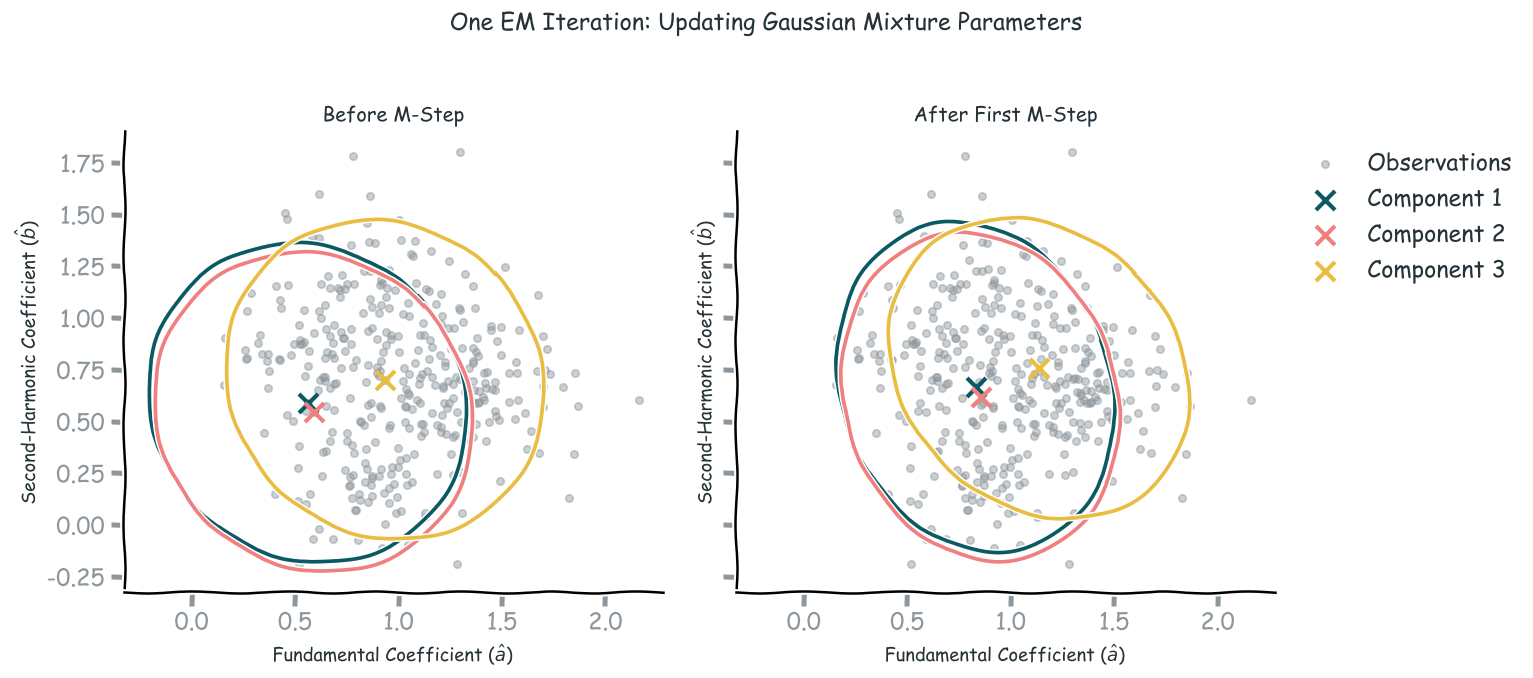

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    sharex=True,
    sharey=True
)

parameter_sets = [
    (
        "Before M-Step",
        weights_init,
        means_init,
        covs_init
    ),
    (
        "After First M-Step",
        weights_1,
        means_1,
        covs_1
    )
]

for ax, (title, weights, means, covs) in zip(
    axes,
    parameter_sets
):

    # Unlabeled observations
    ax.scatter(
        X_unlabeled[:, 0],
        X_unlabeled[:, 1],
        s=20,
        color=GRAY,
        alpha=0.45,
        label="Observations"
    )

    # Gaussian components
    for k in range(K):

        color = CLASS_COLORS[k]

        # Covariance ellipse
        add_covariance_ellipse(
            ax,
            mean=means[k],
            cov=covs[k],
            color=color,
            probability=0.90,
            linewidth=2.2
        )

        # Component mean
        ax.scatter(
            means[k, 0],
            means[k, 1],
            marker="x",
            s=130,
            linewidths=2.5,
            color=color,
            label=f"Component {k + 1}"
        )

    ax.set_title(title)

    ax.set_xlabel(
        r"Fundamental Coefficient ($\hat{a}$)"
    )

    ax.set_ylabel(
        r"Second-Harmonic Coefficient ($\hat{b}$)"
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    #ax.grid(alpha=0.15)

axes[1].legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0)
)

plt.suptitle(
    "One EM Iteration: Updating Gaussian Mixture Parameters",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()

We have now completed one iteration of the Expectation–Maximization algorithm.
Starting from the initial parameters, we performed two operations.

**E-Step**

We estimated the responsibilities of every Gaussian component for every observation:
$$
r_{nk}^{(0)}=
P(
Z_n=k
\mid
\mathbf{x}_n,
\boldsymbol{\theta}^{(0)}
).
$$

**M-Step**

We updated the Gaussian mixture parameters using the responsibilities:
$$
\boldsymbol{\theta}^{(1)}=
\left\{
\pi_k^{(1)},
\boldsymbol{\mu}_k^{(1)},
\boldsymbol{\Sigma}_k^{(1)}
\right\}_{k=1}^{K}.
$$
The observed-data log-likelihood is
$$
\ell(\boldsymbol{\theta})=
\sum_{n=1}^{N}
\log
\left[
\sum_{k=1}^{K}
\pi_k
\mathcal N(
\mathbf{x}_n;
\boldsymbol{\mu}_k,
\boldsymbol{\Sigma}_k
)
\right].
$$
For the standard exact EM algorithm, each iteration satisfies
$$
\boxed{
\ell(\boldsymbol{\theta}^{(t+1)})
\geq
\ell(\boldsymbol{\theta}^{(t)}).
}
$$

**Why Does EM Improve the Likelihood?**

The E-step computes the posterior distribution of the hidden assignments using the current parameters.
The M-step then chooses parameters that maximize the expected complete-data log-likelihood under those responsibilities.
Together, these operations guarantee that the observed-data log-likelihood does not decrease, provided the updates are performed correctly and the required mathematical conditions hold.
The full explanation uses Jensen's inequality and a lower bound on the log-likelihood.

> ** Important Limitations**  
>Likelihood improvement does not guarantee that:
> - The algorithm has found the global maximum.
> - The estimated components match the generating components.
> - The learned components correspond to meaningful physical operating conditions.  
> Also, the first EM iteration does not necessarily produce a good mixture model.
> The algorithm may require many iterations before its parameters stabilize.

### 2.5 The Complete Expectation–Maximization Algorithm

We have implemented the two main operations of the Expectation–Maximization algorithm:

**E-Step — Expectation**

Estimate the posterior responsibilities using the current mixture parameters:
$$
\boxed{
r_{nk}^{(t)}=
P\left(
Z_n=k
\mid
\mathbf{x}_n,\boldsymbol\theta^{(t)}
\right)
}
$$

**M-Step — Maximization**

Update the mixture parameters using the responsibilities:
$$
\boxed{
\boldsymbol\theta^{(t+1)}=
\arg\max_{\boldsymbol\theta}
Q(\boldsymbol\theta\mid\boldsymbol\theta^{(t)})
}
$$
where
$$
Q(\boldsymbol\theta\mid\boldsymbol\theta^{(t)})=
\mathbb E_{Z\mid X,\boldsymbol\theta^{(t)}}
\left[
\log p(X,Z\mid\boldsymbol\theta)
\right].
$$
For Gaussian mixture models, the M-step leads to the weighted maximum-likelihood updates derived previously.

#### Iterative Learning

Starting from an initial parameter estimate $\boldsymbol\theta^{(0)}$, EM repeatedly performs:
1. Compute responsibilities using $\boldsymbol\theta^{(t)}$.
2. Update the mixture parameters to obtain $\boldsymbol\theta^{(t+1)}$.
3. Evaluate the observed-data log-likelihood.
4. Repeat until convergence or a maximum number of iterations is reached.

The observed-data log-likelihood is
$$
\ell(\boldsymbol\theta)=
\sum_{n=1}^{N}
\log
\left[
\sum_{k=1}^{K}
\pi_k
\mathcal N(
\mathbf{x}_n;
\boldsymbol\mu_k,
\boldsymbol\Sigma_k
)
\right].
$$
Under standard exact EM updates, the log-likelihood is non-decreasing:
$$
\boxed{
\ell(\boldsymbol\theta^{(t+1)})
\geq
\ell(\boldsymbol\theta^{(t)})
}
$$
This property is useful for verifying our implementation.
However, it does not guarantee convergence to the global maximum.

#### Numerical Convergence

In practice, we need a stopping criterion.
We will stop when the improvement in observed-data log-likelihood becomes sufficiently small relative to its current magnitude:
$$
\boxed{
\ell^{(t+1)}-\ell^{(t)}
\leq
\varepsilon
\left(
1+|\ell^{(t)}|
\right)
}
$$
where $\varepsilon$ is a small positive tolerance.
We also impose a maximum number of iterations.

**Important:** This is a numerical stopping criterion, not a proof that the algorithm has reached the global optimum or even an exact stationary point.
A small likelihood improvement does not necessarily mean that the component parameters have stopped changing completely.


To understand how EM learns, we will record the parameters after every iteration:

- Mixing weights.
- Component means.
- Component covariance matrices.
- Observed-data log-likelihood.

This will allow us to visualize the evolution of the Gaussian components rather than examining only the final model.
For this experiment, we will continue using an unregularized full-covariance GMM.

In [ ]:
def fit_gmm_em(
    X,
    weights_init,
    means_init,
    covs_init,
    max_iter=300,
    tol=1e-8
):

    weights = np.array(weights_init, copy=True)
    means = np.array(means_init, copy=True)
    covariances = np.array(covs_init, copy=True)

    # Initial E-step and log-likelihood
    responsibilities, log_likelihood = gmm_e_step(
        X,
        weights,
        means,
        covariances
    )

    # Store the initial state (iteration 0)
    history = [{
        "iteration": 0,
        "weights": weights.copy(),
        "means": means.copy(),
        "covariances": covariances.copy(),
        "log_likelihood": float(log_likelihood)
    }]

    converged = False

    # EM iterations
    for iteration in range(1, max_iter + 1):

        # M-step: update parameters from responsibilities
        new_weights, new_means, new_covs = gmm_m_step(
            X,
            responsibilities
        )

        # Check covariance validity
        if np.any(np.linalg.eigvalsh(new_covs) <= 0):
            raise ValueError(
                f"Covariance matrix became singular "
                f"at iteration {iteration}."
            )

        # E-step with updated parameters
        new_responsibilities, new_log_likelihood = gmm_e_step(
            X,
            new_weights,
            new_means,
            new_covs
        )

        # Compute improvement
        improvement = new_log_likelihood - log_likelihood

        # Numerical monotonicity check
        if improvement < -1e-7:
            raise RuntimeError(
                f"Log-likelihood decreased at iteration "
                f"{iteration}: {improvement:.6e}"
            )

        # Update current state
        previous_log_likelihood = log_likelihood

        weights = new_weights
        means = new_means
        covariances = new_covs

        responsibilities = new_responsibilities
        log_likelihood = new_log_likelihood

        # Save updated parameters
        history.append({
            "iteration": iteration,
            "weights": weights.copy(),
            "means": means.copy(),
            "covariances": covariances.copy(),
            "log_likelihood": float(log_likelihood)
        })

        # Check convergence
        threshold = tol * (
            1.0 + abs(previous_log_likelihood)
        )

        if improvement <= threshold:
            converged = True
            break

    return {
        "weights": weights,
        "means": means,
        "covariances": covariances,
        "responsibilities": responsibilities,
        "log_likelihood": float(log_likelihood),
        "n_iter": iteration,
        "converged": converged,
        "history": history
    }

In [ ]:
# Fit the GMM using our EM implementation
em_result = fit_gmm_em(
    X_unlabeled,
    weights_init,
    means_init,
    covs_init,
    max_iter=300,
    tol=1e-8
)

# Extract results
weights_final = em_result["weights"]
means_final = em_result["means"]
covs_final = em_result["covariances"]

R_final = em_result["responsibilities"]

history = em_result["history"]

log_likelihood_history = np.array([
    state["log_likelihood"]
    for state in history
])

# Print results
print("EM Training Summary")
print("-" * 45)

print("Converged:", em_result["converged"])
print("Number of iterations:", em_result["n_iter"])

print(
    f"Initial log-likelihood: "
    f"{log_likelihood_history[0]:.6f}"
)

print(
    f"Final log-likelihood: "
    f"{log_likelihood_history[-1]:.6f}"
)

print(
    f"Total improvement: "
    f"{log_likelihood_history[-1] - log_likelihood_history[0]:.6f}"
)

print("\nFinal mixing weights:")
print(np.round(weights_final, 4))

print("\nFinal component means:")
print(np.round(means_final, 4))

print("\nFinal covariance matrices:")
print(np.round(covs_final, 4))


# Validation checks
assert len(history) == em_result["n_iter"] + 1

assert np.all(
    np.diff(log_likelihood_history) >= -1e-7
)

assert np.all(weights_final > 0)

assert np.isclose(
    weights_final.sum(),
    1.0
)

assert np.all(
    np.linalg.eigvalsh(covs_final) > 0
)

assert np.allclose(
    R_final.sum(axis=1),
    1.0
)


assert np.allclose(
    history[1]["weights"],
    weights_1,
    atol=1e-10
)

assert np.allclose(
    history[1]["means"],
    means_1,
    atol=1e-10
)

assert np.allclose(
    history[1]["covariances"],
    covs_1,
    atol=1e-10
)

assert np.isclose(
    history[1]["log_likelihood"],
    log_likelihood_1,
    atol=1e-10
)

print("\nAll EM validation checks passed.")

EM Training Summary
---------------------------------------------
Converged: True
Number of iterations: 140
Initial log-likelihood: -399.236304
Final log-likelihood: -249.515295
Total improvement: 149.721010

Final mixing weights:
[0.3809 0.189  0.43  ]

Final component means:
[[0.7343 0.9715]
 [0.8621 0.2104]
 [1.2823 0.6796]]

Final covariance matrices:
[[[ 0.0687  0.0223]
  [ 0.0223  0.0806]]

 [[ 0.0376  0.0002]
  [ 0.0002  0.0315]]

 [[ 0.0702 -0.0048]
  [-0.0048  0.0436]]]

All EM validation checks passed.


### 2.6 Visualizing the Learning Process

In this section, we will investigate two complementary aspects of learning.

**1. Parameter Evolution**

We will visualize the Gaussian components at several stages:
- Initialization.
- After the first iteration.
- During training.
- At the final iteration.

For each component, we will display:
- Its estimated mean.
- Its covariance ellipse.
- The unlabeled observations.

This will help us understand how responsibilities influence parameter estimation.

**2. Log-Likelihood Convergence**

We will track the observed-data log-likelihood:
$$
\ell^{(t)}=
\ell(\boldsymbol\theta^{(t)}).
$$
A correct implementation of standard EM should produce a non-decreasing likelihood sequence.
However, the magnitude of improvement may vary considerably between iterations.
For example, the initial iterations may produce large changes, while later iterations produce smaller refinements.
An important question is:

> Does a large improvement in likelihood necessarily mean that the Gaussian components have become physically meaningful?

The answer is no.
Likelihood measures how well the probabilistic model explains the observations under its assumptions.
It does not directly measure agreement with the original operating-condition labels.
We will revisit this distinction when interpreting the final model.

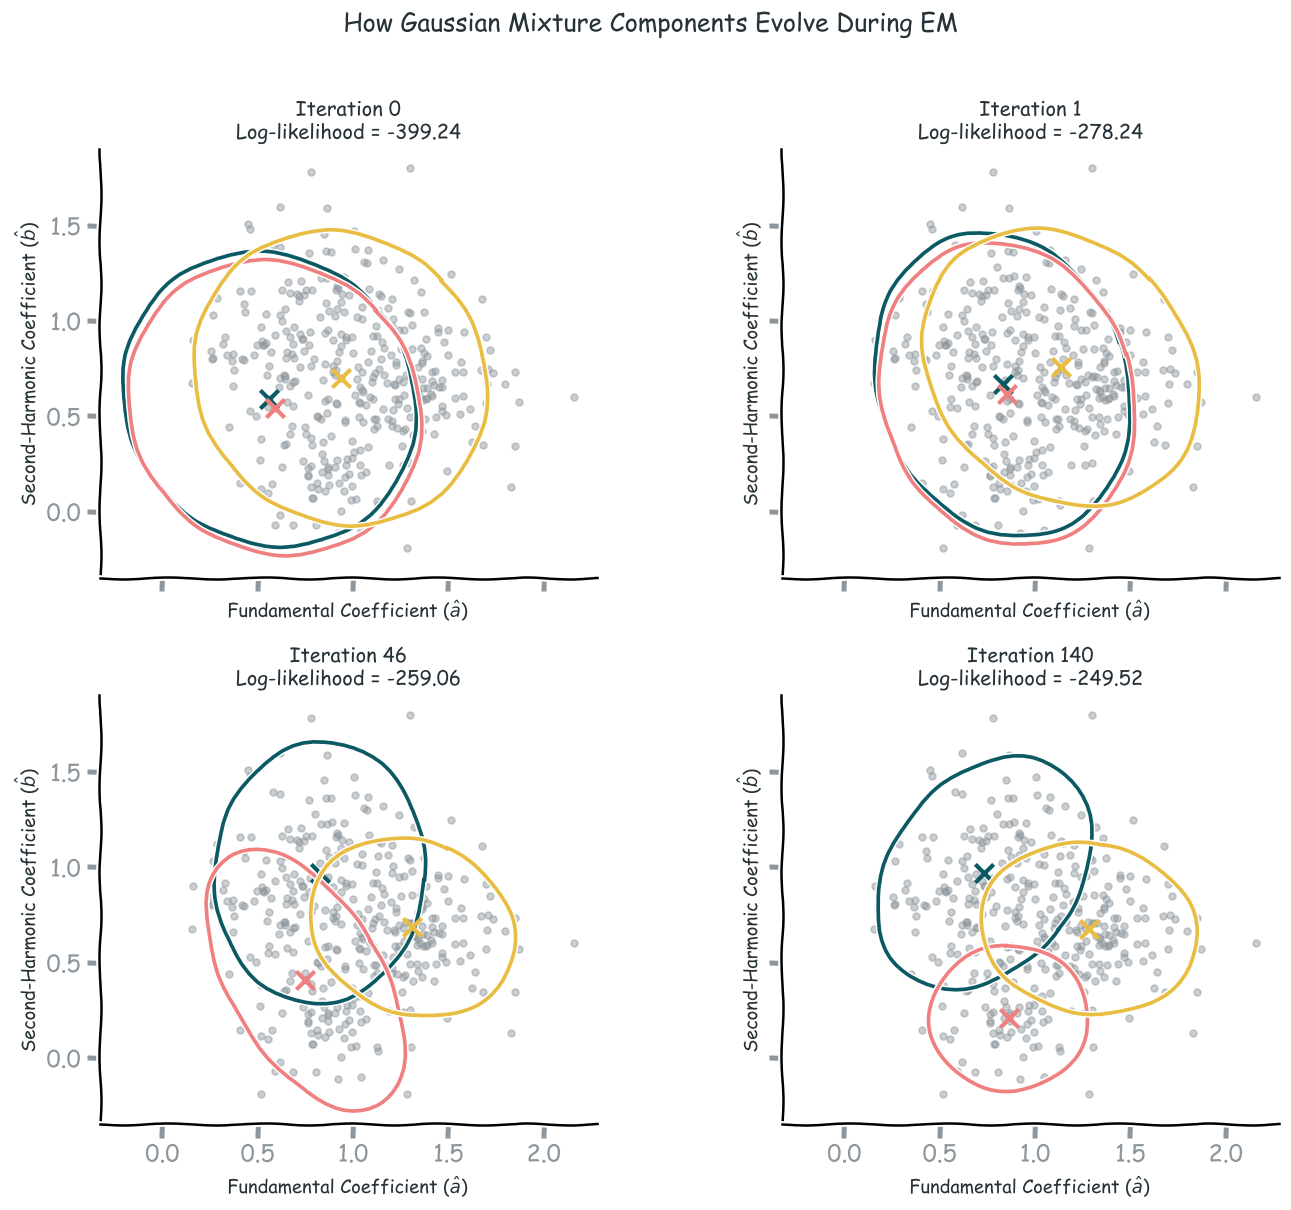

In [ ]:
# Select EM iterations for visualization
n_iter = em_result["n_iter"]

snapshot_iterations = [
    0,
    1,
    max(2, n_iter // 3),
    n_iter
]

# Plot Gaussian components at selected iterations
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    sharey=True
)

axes = axes.ravel()

for ax, iteration in zip(
    axes,
    snapshot_iterations
):

    state = history[iteration]

    means = state["means"]
    covariances = state["covariances"]
    weights = state["weights"]

    # Plot unlabeled observations
    ax.scatter(
        X_unlabeled[:, 0],
        X_unlabeled[:, 1],
        s=17,
        color=GRAY,
        alpha=0.45
    )

    # Plot Gaussian components
    for k in range(K):

        color = CLASS_COLORS[k]

        add_covariance_ellipse(
            ax,
            mean=means[k],
            cov=covariances[k],
            color=color,
            probability=0.90,
            linewidth=2.2
        )

        ax.scatter(
            means[k, 0],
            means[k, 1],
            marker="x",
            s=120,
            linewidths=2.5,
            color=color
        )

    ax.set_title(
        f"Iteration {iteration}\n"
        f"Log-likelihood = {state['log_likelihood']:.2f}"
    )

    ax.set_xlabel(
        r"Fundamental Coefficient ($\hat{a}$)"
    )

    ax.set_ylabel(
        r"Second-Harmonic Coefficient ($\hat{b}$)"
    )

    ax.set_aspect("equal", adjustable="box")
    #ax.grid(alpha=0.12)

plt.suptitle(
    "How Gaussian Mixture Components Evolve During EM",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

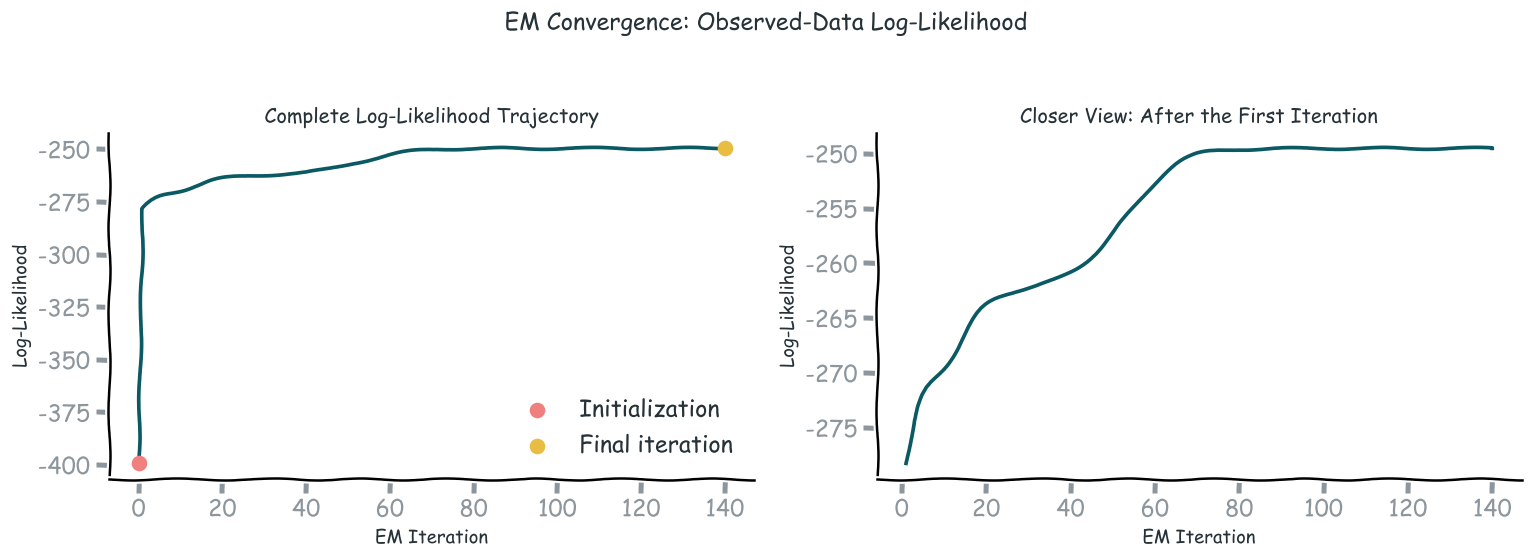

Likelihood Improvement Summary
---------------------------------------------
First iteration improvement: 120.997504
Last iteration improvement: 0.00000225
Minimum iteration improvement: 0.00000225
Maximum iteration improvement: 120.997504


In [ ]:
# Log-likelihood convergence
iterations = np.arange(
    len(log_likelihood_history)
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

# Left: Complete trajectory
axes[0].plot(
    iterations,
    log_likelihood_history,
    color=TEAL,
    linewidth=2.2
)

axes[0].scatter(
    iterations[0],
    log_likelihood_history[0],
    color=RED,
    s=70,
    zorder=3,
    label="Initialization"
)

axes[0].scatter(
    iterations[-1],
    log_likelihood_history[-1],
    color=YELLOW,
    s=70,
    zorder=3,
    label="Final iteration"
)

axes[0].set_title(
    "Complete Log-Likelihood Trajectory"
)

axes[0].set_xlabel("EM Iteration")
axes[0].set_ylabel("Log-Likelihood")

axes[0].legend(frameon=False)
axes[0].grid(alpha=0.15)


# Right: Convergence after the first iteration
axes[1].plot(
    iterations[1:],
    log_likelihood_history[1:],
    color=TEAL,
    linewidth=2.2
)

axes[1].set_title(
    "Closer View: After the First Iteration"
)

axes[1].set_xlabel("EM Iteration")
axes[1].set_ylabel("Log-Likelihood")

axes[1].grid(alpha=0.15)


plt.suptitle(
    "EM Convergence: Observed-Data Log-Likelihood",
    fontsize=14,
    y=1.04
)

plt.tight_layout()
plt.show()

# Quantify likelihood improvements
improvements = np.diff(
    log_likelihood_history
)

print("Likelihood Improvement Summary")
print("-" * 45)

print(
    f"First iteration improvement: "
    f"{improvements[0]:.6f}"
)

print(
    f"Last iteration improvement: "
    f"{improvements[-1]:.8f}"
)

print(
    f"Minimum iteration improvement: "
    f"{improvements.min():.8f}"
)

print(
    f"Maximum iteration improvement: "
    f"{improvements.max():.6f}"
)

### 2.7 Did EM Recover the Generating Structure?

Our Gaussian mixture model has converged.
The observed-data log-likelihood increased, and the estimated Gaussian components evolved into distinct distributions.
However, successful likelihood optimization does not necessarily mean that the learned components correspond to the physical operating conditions.
Since our dataset is synthetic, we know the generating class labels.
Although these labels were not used during EM fitting, we can now use them to evaluate how closely the inferred components agree with the original classes.

#### 1. Hard Assignments from Responsibilities

The GMM produces a responsibility vector for each observation:
$$
\mathbf r_n =
[r_{n1},r_{n2},\ldots,r_{nK}].
$$
A hard component assignment can be obtained using
$$
\boxed{
\hat z_n = \arg\max_k r_{nk}.
}
$$
This selects the component with the highest posterior responsibility.
However, converting responsibilities into hard assignments discards information about uncertainty.
For example, the responsibility vectors
$$
[0.95,\ 0.03,\ 0.02]
$$
and
$$
[0.36,\ 0.34,\ 0.30]
$$
produce the same hard assignment, even though the second observation is much more ambiguous.

#### 2. Comparing Clusters with Generating Classes

A complication arises when comparing GMM component indices with the original class labels.
Mixture components have arbitrary indices.
For example, a model with components
$$
(1,2,3)
$$
represents exactly the same mixture density if we consistently permute the component parameters and indices.
Consequently, Component 1 does not necessarily correspond to Class 1.
We should not directly calculate classification accuracy by comparing the raw component indices with the generating class indices.
Instead, we can use a metric that is invariant to label permutations.

#### 3. Adjusted Rand Index (ARI)

The **Adjusted Rand Index** measures agreement between two partitions of the same observations.
It compares which pairs of observations are assigned to the same or different groups, while adjusting for agreement expected by chance.
Important properties:
- ARI = 1 indicates identical partitions, up to a permutation of labels.
- ARI ≈ 0 indicates agreement comparable to chance under the adjustment model.
- ARI can be negative when agreement is worse than its chance-adjusted baseline.

We will use ARI to compare the GMM assignments with the known generating labels.
A higher ARI indicates stronger agreement with the generating partition.
However, ARI is not a measure of likelihood or probability calibration.
Furthermore, because the generating Gaussian populations overlap, perfect recovery of individual assignments is not generally possible from the observed features alone.

We will evaluate:

1. Initial hard component assignments.
2. Final hard component assignments.
3. Agreement with the generating classes.
4. Final probabilistic responsibilities.

This will help us distinguish **optimization performance**, **clustering agreement**, and **assignment uncertainty**.

In [ ]:
from sklearn.metrics import adjusted_rand_score


#  labels were not used during GMM fitting.
labels_eval = labels_train[shuffle_idx]


# Initial and final hard assignments
assignments_init = np.argmax(
    R_init,
    axis=1
)

assignments_final = np.argmax(
    R_final,
    axis=1
)


# Adjusted Rand Index
ari_init = adjusted_rand_score(
    labels_eval,
    assignments_init
)

ari_final = adjusted_rand_score(
    labels_eval,
    assignments_final
)


# Compare initial and final assignments
changed_assignments = np.sum(
    assignments_init != assignments_final
)

print("GMM Clustering Evaluation")
print("-" * 45)

print(f"Initial ARI: {ari_init:.4f}")
print(f"Final ARI:   {ari_final:.4f}")

print(
    f"\nObservations with changed hard assignments: "
    f"{changed_assignments} / {N}"
)

print(
    f"Percentage changed: "
    f"{100 * changed_assignments / N:.2f}%"
)


# Component assignment counts
print("\nFinal hard-assignment counts:")

for k in range(K):

    count = np.sum(
        assignments_final == k
    )

    print(
        f"Component {k + 1}: {count}"
    )


# Contingency table: generating classes vs. components
contingency = np.zeros(
    (N_CLASSES, K),
    dtype=int
)

np.add.at(
    contingency,
    (labels_eval, assignments_final),
    1
)

print("\nGenerating Classes vs. Inferred Components")
print("-" * 45)

header = "Class".ljust(15)

for k in range(K):
    header += f"Comp. {k+1:>2}  "

print(header)

for k, name in enumerate(CLASS_NAMES):

    row = name.ljust(15)

    for j in range(K):
        row += f"{contingency[k, j]:>7}  "

    print(row)


# Numerical checks
assert contingency.sum() == N

assert np.all(
    contingency.sum(axis=1)
    == N_TRAIN_PER_CLASS
)

assert np.array_equal(
    contingency.sum(axis=0),
    np.bincount(
        assignments_final,
        minlength=K
    )
)

print("\nEvaluation checks passed.")

GMM Clustering Evaluation
---------------------------------------------
Initial ARI: 0.1231
Final ARI:   0.3582

Observations with changed hard assignments: 108 / 360
Percentage changed: 30.00%

Final hard-assignment counts:
Component 1: 137
Component 2: 70
Component 3: 153

Generating Classes vs. Inferred Components
---------------------------------------------
Class          Comp.  1  Comp.  2  Comp.  3  
Normal               6       64       50  
High Load           29        0       91  
Abnormal           102        6       12  

Evaluation checks passed.


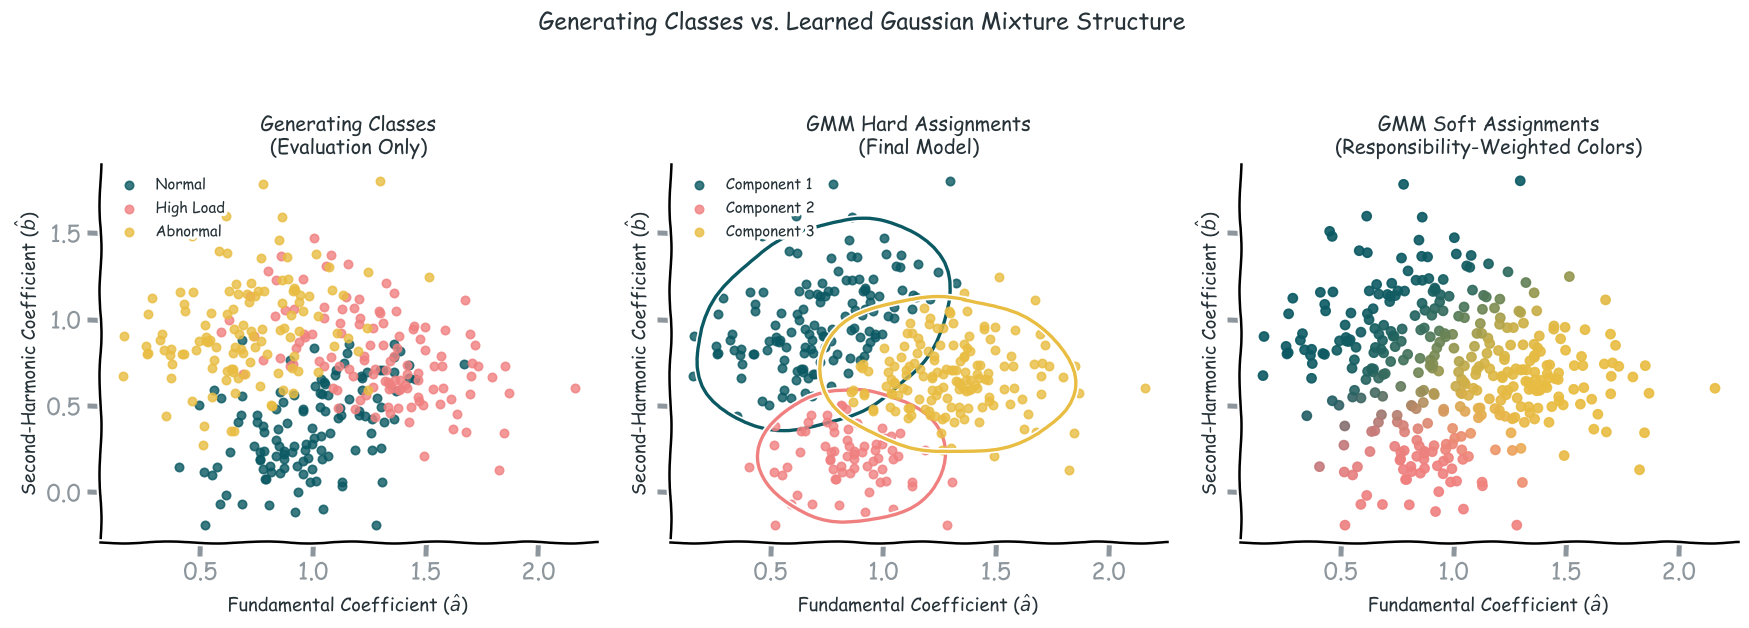

In [ ]:
from matplotlib.colors import to_rgb


component_rgb = np.array([
    to_rgb(color)
    for color in CLASS_COLORS
])

soft_colors = R_final @ component_rgb


# Compare generating and inferred structure
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)


# Panel 1: Generating classes
ax = axes[0]

for k in range(N_CLASSES):

    mask = labels_eval == k

    ax.scatter(
        X_unlabeled[mask, 0],
        X_unlabeled[mask, 1],
        s=25,
        color=CLASS_COLORS[k],
        alpha=0.8,
        label=CLASS_NAMES[k]
    )

ax.set_title(
    "Generating Classes\n(Evaluation Only)"
)

ax.legend(
    frameon=False,
    loc="upper left",
    fontsize=9
)

# Panel 2: Final hard assignments
ax = axes[1]

for k in range(K):

    mask = assignments_final == k

    ax.scatter(
        X_unlabeled[mask, 0],
        X_unlabeled[mask, 1],
        s=25,
        color=CLASS_COLORS[k],
        alpha=0.8,
        label=f"Component {k + 1}"
    )

    add_covariance_ellipse(
        ax,
        mean=means_final[k],
        cov=covs_final[k],
        color=CLASS_COLORS[k],
        probability=0.90,
        linewidth=2.0
    )

ax.set_title(
    "GMM Hard Assignments\n(Final Model)"
)

ax.legend(
    frameon=False,
    loc="upper left",
    fontsize=9
)

# Panel 3: Final soft responsibilities
ax = axes[2]

ax.scatter(
    X_unlabeled[:, 0],
    X_unlabeled[:, 1],
    s=30,
    c=soft_colors,
    alpha=0.9
)

ax.set_title(
    "GMM Soft Assignments\n(Responsibility-Weighted Colors)"
)


# Formatting
for ax in axes:

    ax.set_xlabel(
        r"Fundamental Coefficient ($\hat{a}$)"
    )

    ax.set_ylabel(
        r"Second-Harmonic Coefficient ($\hat{b}$)"
    )

    #ax.grid(alpha=0.12)

plt.suptitle(
    "Generating Classes vs. Learned Gaussian Mixture Structure",
    fontsize=14,
    y=1.05
)

plt.tight_layout()
plt.show()

In [ ]:
# Compare initial and final responsibilities
print("Responsibility Evolution")
print("-" * 50)

for name, idx in zip(
    selected_names,
    selected_indices
):

    print(f"\n{name} observation")
    print(f"Index: {idx}")

    print(
        "Features:",
        np.round(X_unlabeled[idx], 4)
    )

    print(
        "Initial responsibilities:",
        np.round(R_init[idx], 4)
    )

    print(
        "Final responsibilities:  ",
        np.round(R_final[idx], 4)
    )

    print(
        "Initial hard assignment:",
        np.argmax(R_init[idx]) + 1
    )

    print(
        "Final hard assignment:  ",
        np.argmax(R_final[idx]) + 1
    )

Responsibility Evolution
--------------------------------------------------

Most confident observation
Index: 47
Features: [2.1608 0.6023]
Initial responsibilities: [0.0146 0.0197 0.9657]
Final responsibilities:   [0. 0. 1.]
Initial hard assignment: 3
Final hard assignment:   3

Most ambiguous observation
Index: 281
Features: [0.7658 0.613 ]
Initial responsibilities: [0.3288 0.3363 0.3349]
Final responsibilities:   [0.6006 0.1048 0.2946]
Initial hard assignment: 2
Final hard assignment:   1


### 2.8 Experiment 2 Interpretation


We have now trained a Gaussian Mixture Model without using the generating class labels.
The model learned:

- Mixing weights describing the estimated proportions of the Gaussian components.
- Mean vectors describing their centers.
- Covariance matrices describing their shapes and orientations.
- Responsibilities describing probabilistic assignments of observations to components.

We also observed how these quantities changed during EM.

#### Optimization vs. Structure Recovery

The observed-data log-likelihood improved throughout training.
This confirms that the algorithm successfully optimized the mixture likelihood under the specified EM procedure and stopping criterion.
However, maximizing likelihood and recovering the generating component assignments are different objectives.
A fitted mixture may explain the observed distribution well without perfectly reproducing the original class assignments.
In particular:

- Overlapping Gaussian components make individual assignments uncertain.
- Finite training data introduce parameter-estimation variability.
- EM can converge to different solutions depending on initialization.
- The inferred component indices have no intrinsic physical meaning.

>**Main Note:**  
> Expectation–Maximization provides a principled way to learn probabilistic models with hidden variables, but successful optimization does not guarantee recovery of the true or physically meaningful structure.

This distinction is important whenever mixture models are applied to real signal-processing problems.